<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/HybridQNN_LabelPoisoning_Kundu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN under data poisoning: the QUID label-flipping attack (Kundu and Ghosh) step by step

This notebook re-implements, runs and checks the method of

> Satwik Kundu and Swaroop Ghosh,
> "Adversarial Data Poisoning Attacks on Quantum Machine Learning in the NISQ Era",
> arXiv:2411.14412 [quant-ph], v3, 30 April 2025 (first posted November 2024). https://arxiv.org/abs/2411.14412
> (the repository manifest lists it as "Adversarial poisoning attack on quantum machine learning models", 2024).

The paper publishes no code, so everything below is written from the method as the paper describes it. The paper uses
PennyLane; so does this notebook for *checking* its circuits, but the training loops run on a small density-matrix simulator
written in NumPy (it is exact, much faster than `default.mixed` for this job, and the notebook proves its
agreement with PennyLane's `default.mixed` to 1e-12 before using it).

**What the notebook does.**
1. Downloads four public image sets (MNIST, Fashion-MNIST, Kuzushiji-MNIST, EMNIST letters), builds the paper's four
   4-class tasks (MNIST-4, Fashion-4, Kuzushiji-4, Letters-4, 1000 images each, 700 train / 300 test) and compresses each image
   to 8 numbers.
2. Builds the paper's victim, a small *hybrid QNN* (angle encoding, a parameterised circuit "PQC-1", "PQC-6" or "PQC-8",
   Pauli-Z read-out, a classical linear layer), trained with Adam and a SPSA gradient, under no noise, under the paper's
   amplitude-damping plus depolarising noise, and under noise derived from the calibration of two IBM devices.
3. Implements **intra-class encoder state similarity (ESS)** and the **QUID** attack: the label of each poisoned training sample
   is set to the class whose encoded quantum states are *farthest* from it in Hilbert space. No victim training is needed.
4. Compares QUID with random label flipping, with the bi-level variant (random features plus labels), across poison ratios,
   circuits, noise levels, a partition-aggregation defence and an 8-qubit, 10-class model, and re-draws the paper's figures.
5. Trains classical models (SVC, random forest, logistic regression) on the same inputs and the same poisoned labels, to show
   whether the attack is specific to the quantum model.
6. Prints every number of the paper next to the notebook's number, with a verdict per claim, and discusses the result critically.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
pinned versions; if Colab asks to restart the session, restart and run all again. No GPU and no IBM Quantum account are needed.

**Runtime.** `FAST_MODE = True` (class demo) takes about 8 minutes on a CPU and uses 2 repetitions, 6-epoch deep-circuit training and
only the poison ratio 0.5 for PQC-6 / PQC-8; `FAST_MODE = False` follows the paper's budgets (30 epochs, batch 32, learning rate 0.01, 700 / 300 samples) with five
repetitions of every PQC-1 experiment and two of the deep PQC-6 / PQC-8 experiments (51 minutes on the 8-core machine used for validation, shared with other jobs; the committed outputs are from this full run).

**What you get at the end.** The ESS / QUID label-accuracy tables, the poisoned-accuracy tables for noiseless, noisy and
device-noise training, the poison-ratio sweep, the defence and scalability experiments, the classical-model comparison, and a table
"paper vs this notebook" with a verdict for each claim.

## The paper in one page

**Threat.** A victim sends a training set $\mathcal{D}_{tr}$ and a quantum neural network (QNN) to a quantum cloud provider for
training. An adversary inside the cloud (a rogue insider or an intruder) can change the data on the way. Here the adversary
only changes **labels** of a fraction $\varepsilon$ of the training samples (label flipping, indiscriminate: the goal is to ruin
accuracy on the whole test set). The adversary knows the training data and the **encoding circuit** of the QNN (gray-box), but not the
rest of the circuit, the loss, the optimiser or the hyper-parameters, and does not train anything.

**Victim (Fig. 1).** Hybrid QNN: classical features become rotation angles of a data-encoding circuit; a parameterised quantum circuit
(PQC) transforms the state; Pauli-Z expectation values of all qubits feed a classical linear layer with one neuron per class.
PQC-1, PQC-6 and PQC-8 are circuits 1, 6 and 8 of Sim et al. (2019); 4 qubits (8 qubits and two layers in the scalability test).

**Method.**
* *Intra-class encoder state similarity (ESS, Sec. 4.1).* Run the encoding circuit, get a density matrix $\rho(x)$ per sample, measure
  distances $d(\sigma,\rho)$ between density matrices (Frobenius norm, trace norm, or $1-|\mathrm{Tr}(\sigma^\dagger\rho)|/\dim$), average
  them per class, and the *nearest* class is a good guess of the true label (Table 2, Fig. 3, Fig. 4).
* *QUID (Algorithm 1).* Split $\mathcal{D}_{tr}$ into a clean part and a poisoned part (ratio $\varepsilon$). For every poisoned sample give the
  label of the class whose clean encoded states are **farthest** (largest mean Frobenius distance). A greedy, training-free label flip.

**Experimental setup (Sec. 5.1).** PennyLane `lightning.qubit` (noiseless) and `default.mixed` with amplitude damping *and*
depolarising noise of probability $p = 0.05$ after every gate (noisy), SPSA gradients, Adam, learning rate 0.01, batch 32,
30 epochs, cross-entropy, 1000 shots, random initial weights. Noise models of IBM_Brisbane and IBM_Kyiv through `qiskit.aer`.
Data: MNIST, Fashion-MNIST, Kuzushiji-MNIST and EMNIST letters, each reduced to $d = 8$ latent numbers by a convolutional
autoencoder, four classes each (MNIST-4: digits 0-3; Fashion-4: classes 6-9; Kuzushiji-4: classes 3, 5, 6, 9; Letters-4: letters 1-4),
1000 samples, 700 train / 300 test, two features per qubit.

**Claims (all accuracies are test accuracy in %).**

| Source | Claim |
|---|---|
| Table 2, Fig. 3 | Nearest-class label from ESS is right for 90 % (MNIST), 91 %, 75 %, 86 % of samples with the Frobenius norm; the Frobenius norm is as good as the others and 3 to 5 times cheaper. |
| Fig. 4 | With a noisy encoder, amplitude encoding keeps its ESS accuracy (about 88 %) while 4-rotation-per-qubit angle encoding falls from 62 % to 45 %. |
| Table 4 (eps = 0.5) | QUID cuts accuracy from 94 / 85 / 81 / 89 % to 44 / 32 / 37 / 30 % (noiseless) and to 32 / 8 / 27 / 13 % (noise p = 0.05), random flipping only to about 91 / 83 / 75 / 78 %. |
| Table 3 | Label-flip QUID is more damaging than bi-level QUID (random features plus QUID labels). |
| Table 5 | Under IBM_Brisbane / IBM_Kyiv noise models QUID drives accuracy to about 10 %, a drop of about 73 points. |
| Table 6 | Accuracy vs poison ratio and circuit: tiny effect at eps <= 0.1; below chance (25 %) at eps = 0.7 for PQC-1 (the paper's text says "for eps > 0.5"); QUID is less effective on the noisy, deep PQC-6. |
| Table 7 | A partition-aggregation + semi-supervised defence (SS-DPA, k = 3) helps little. |
| Sec. 6 | An 8-qubit, two-layer QNN on 10-class MNIST (d = 16, 2000 samples) loses about 41 more points and gains about 0.4 more test loss under QUID than under random flipping. |
| Abstract | Up to 92 points of accuracy degradation vs the clean model and up to 75 vs random flipping. |

### What follows the paper and what had to be chosen

The paper describes the idea and the experiments in six pages and leaves many details open. Every choice below is marked `# CHOICE:` where it appears in code.

| Item | Paper | This notebook |
|---|---|---|
| Latent features | convolutional autoencoder (architecture not given), d = 8 (d = 16 for MNIST-10) | PCA to 8 (16) components, fitted on the training split only, then min-max to $[0,\pi]$ (test values clipped) |
| Data | MNIST-4 / Fashion-4 / Kuzushiji-4 / Letters-4, 1000 samples each, 700 train / 300 test | same classes; class-balanced random draw of 250 per class from the public training files, stratified 700 / 300 split, redrawn for every repetition |
| Encoding circuit | angle encoding with $R_Z$ and $R_X$, two features per qubit (Fig. 1 shows H and $R_Z$ for one feature) | $R_X$ then $R_Z$, no Hadamard; qubit q takes component q for $R_X$ and q+4 for $R_Z$. Picked on a validation split of the training data (Sec. 2.2): H,RZ,RX and H,RX,RZ score 57 % and 42 %, RX,RZ 90 % |
| PQC | PQC-1, PQC-6, PQC-8 of Sim et al. | gate lists reconstructed from that paper (PQC-1: 8 parameters, PQC-8: 19, PQC-6: 28) |
| Read-out | Pauli-Z expectation values, linear layer with one neuron per class | the same; weights initialised uniformly in $[0, 2\pi)$ (circuit) and like `torch.nn.Linear` (linear layer) |
| Noise | amplitude damping and depolarising channel, p = 0.05 after each gate | the same; order amplitude damping then depolarising (not stated); checked against PennyLane `default.mixed` |
| Device noise | IBM_Brisbane and IBM_Kyiv noise models in `qiskit.aer` | reduced model built from the calibration of `FakeBrisbane` / `FakeKyiv` (qubits 0 to 3), cross-checked against `qiskit-aer` |
| Training | Adam, lr 0.01, batch 32, 30 epochs, cross-entropy, SPSA gradients, 1000 shots | the same; SPSA step 0.1 rad, Rademacher signs, exact gradient for the linear layer, exact expectation values (no shot noise) |
| Reported accuracy | test accuracy, epoch not stated, repetitions not stated | final-epoch test accuracy, mean and std over 5 repetitions (2 for PQC-6 / PQC-8) |
| Random label flipping | not specified | each selected label becomes a random *different* class; same poisoned subset as QUID |
| Poisoned subset | random split with ratio eps | random subset of round(eps x 700) samples |
| Bi-level poisoning | random features plus labels | random features uniform in $[0,\pi]^8$; QUID labels computed for the random states, random labels for the random baseline |
| ESS evaluation | accuracy of min-distance labels, sample sizes not given (600 evaluated, from the denominators) | 1200 drawn, 600 reference + 600 evaluated, 2 draws |
| ESS metrics | Frobenius, trace, $1-\lvert\mathrm{Tr}(\sigma^\dagger\rho)\rvert/\dim$ | the same; the normalised HS formula is read with dim = $2^n$ |
| Amplitude encoding under noise | not specified | Mottonen decomposition with noise after every gate, and a variant with one noisy state-preparation operation |
| Defence | SS-DPA (DPA plus semi-supervised learning), k = 3 | plain DPA, k = 3, majority vote (semi-supervised part not implemented) |
| 8-qubit test | two-layer PQC-1, MNIST-10, noise not stated | p = 0.05 (paper's default noisy setting, chosen in advance) plus a noiseless side check |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and Pillow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "huggingface_hub", "pyarrow")
           if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in a few minutes (fewer seeds, shorter deep-circuit training).
                           # False: the paper's budgets, five repetitions of the PQC-1 experiments (about one hour on a 2-core CPU).
SEED       = 42            # CHOICE: the paper gives no seed. Repetition k uses seed SEED + k for data draw, split, poison subset, weights, SPSA.
N_SEEDS       = 2 if FAST_MODE else 5     # repetitions of every PQC-1 experiment (mean +- std over data draws, poison subsets, initial weights)
N_SEEDS_DEEP  = 1 if FAST_MODE else 2     # repetitions of the PQC-6 / PQC-8 experiments (about 25 s and 60 s per training)
SEEDS         = [SEED + k for k in range(N_SEEDS)]
SEEDS_DEEP    = [SEED + k for k in range(N_SEEDS_DEEP)]

# --- the paper's data and training budget (Sec. 5.1) ---
N_QUBITS   = 4             # 4-qubit QNN, two features per qubit (d = 8 latent numbers)
N_FEATURES = 8
N_SAMPLES  = 1000          # per 4-class dataset: 700 train / 300 test
TEST_FRAC  = 0.3
EPOCHS     = 30            # paper: 30
EPOCHS_DEEP = 6 if FAST_MODE else 30
LR         = 0.01          # paper: Adam, learning rate 0.01
BATCH      = 32            # paper: 32
SPSA_C     = 0.1           # CHOICE: SPSA perturbation size (radians); the paper does not give it
P_NOISE    = 0.05          # paper: amplitude damping + depolarising probability after each gate
P_NOISE_T3 = 0.10          # paper: Table 3 uses p = 0.1
SHOTS      = None          # CHOICE: exact expectation values. The paper says 1000 shots, but with SPSA and a 0.1 rad step it does not state
                           #         how shot noise enters training; exact expectations isolate the effect of the attack
# --- ESS experiments (Table 2, Fig. 3, Fig. 4): denominators in the paper (e.g. 91.83 = 551/600) imply 600 evaluated samples ---
N_ESS       = 600 if FAST_MODE else 1200     # samples drawn; half are the clean reference, half are evaluated
ESS_TRACE_EVAL = 150 if FAST_MODE else None  # trace norm needs one eigen-decomposition per pair: evaluate only this many samples in FAST mode
NOISE_LEVELS_FIG4 = [0.0, 0.05, 0.1, 0.2]
ESS_SEEDS   = SEEDS[:1] if FAST_MODE else SEEDS[:2]   # independent data draws for the ESS experiments (the trace norm makes them slow)
# --- experiment grids ---
EPS_GRID       = [0.1, 0.3, 0.5, 0.7]                       # paper Table 6
EPS_GRID_DEEP  = [0.5] if FAST_MODE else [0.1, 0.3, 0.5, 0.7]
N_FIG5     = 2000          # Sec. 6: 8-qubit, 2-layer QNN, MNIST-10, d = 16, 2000 samples, 70 : 30
DATA_DIR   = "data"        # downloaded image files are cached here (relative to the working directory)
IBM_TOKEN  = ""            # optional: only needed if you want to adapt the notebook to real hardware; not used here
print(f"FAST_MODE={FAST_MODE} | PQC-1 seeds {SEEDS} | deep-circuit seeds {SEEDS_DEEP} | epochs {EPOCHS} (deep {EPOCHS_DEEP})")

FAST_MODE=False | PQC-1 seeds [42, 43, 44, 45, 46] | deep-circuit seeds [42, 43] | epochs 30 (deep 30)


In [3]:
import os, io, gzip, time, struct, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sklearn, scipy
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import pennylane as qml
import qiskit, qiskit_aer

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(SEED)            # every experiment below builds its own generator from SEED + k
os.makedirs(DATA_DIR, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
T_NOTEBOOK_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2


## 1. Data: four image sets and the paper's four 4-class tasks

The paper uses MNIST, Fashion-MNIST, Kuzushiji-MNIST and EMNIST letters, because they are well known and small enough for a few
qubits after compression. We download the **training files** of the four sets (no registration needed) and cache them in `DATA_DIR`.
MNIST and Fashion-MNIST come from public mirrors; Kuzushiji-MNIST from its official site with a Hugging Face mirror as fallback;
EMNIST letters from a Hugging Face mirror (the EMNIST images are stored transposed, which we undo).

Every task has four classes and 1000 images (250 per class), as in the paper:

| Task | Source | Classes |
|---|---|---|
| MNIST-4 | MNIST | digits 0, 1, 2, 3 |
| Fashion-4 | Fashion-MNIST | classes 6, 7, 8, 9 (shirt, sneaker, bag, ankle boot) |
| Kuzushiji-4 | Kuzushiji-MNIST | classes 3, 5, 6, 9 |
| Letters-4 | EMNIST letters | letters 1, 2, 3, 4 (a, b, c, d) |

mnist     :  60000 images of 28x28, 10 classes
fashion   :  60000 images of 28x28, 10 classes
kuzushiji :  60000 images of 28x28, 10 classes
letters   : 124800 images of 28x28, 26 classes
loaded in 3 s


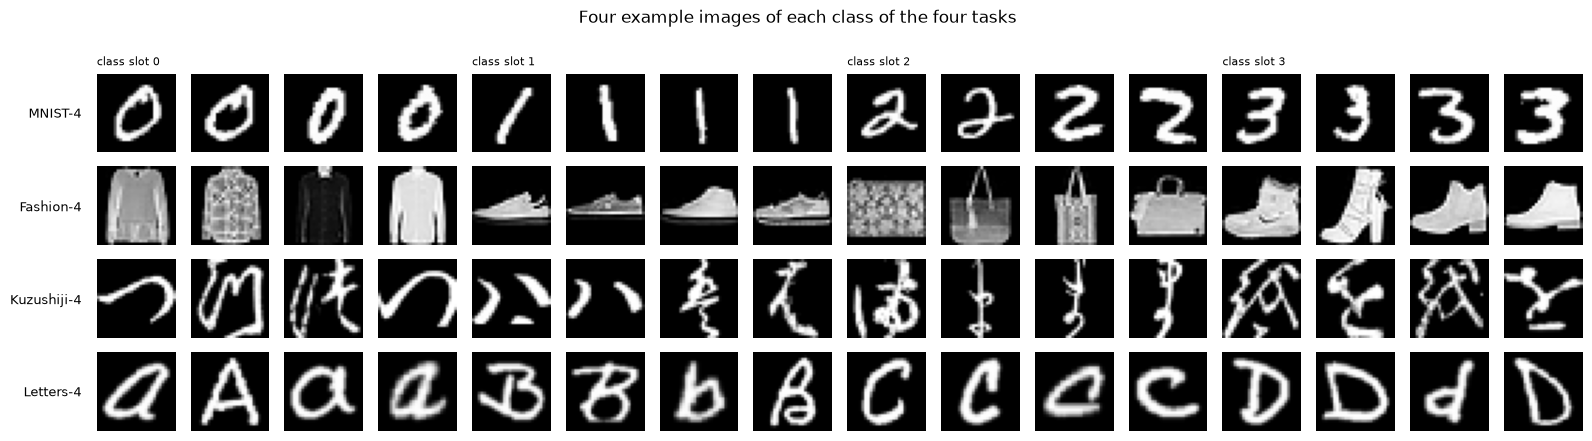

In [4]:
IDX_SOURCES = {
    "mnist":   ["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"],
    "fashion": ["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/{f}",
                "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{f}"],
    "kuzushiji": ["http://codh.rois.ac.jp/kmnist/dataset/kmnist/{f}"],
}
IDX_FILES = {"mnist": ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
             "fashion": ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
             "kuzushiji": ("kmnist-train-imgs.npz", "kmnist-train-labels.npz")}
HF_LETTERS = ("Royc30ne/emnist-letters", "emnist-letters-train-images-idx3-ubyte.gz", "emnist-letters-train-labels-idx1-ubyte.gz")

def _read_idx(raw):
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _download(urls, path):
    import requests
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=(10, 120)); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            last = e; print("  download failed:", u, type(e).__name__)
    raise RuntimeError(f"all mirrors failed for {path}: {last}")

def load_images(name, data_dir=DATA_DIR):
    """Return (images uint8 (N,28,28), labels (N,)) of the train split of a dataset; cached as a compressed npz."""
    cache = os.path.join(data_dir, f"{name}_train.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["x"], z["y"]
    if name in ("mnist", "fashion"):
        fi, fl = IDX_FILES[name]
        pi = _download([u.format(f=fi) for u in IDX_SOURCES[name]], os.path.join(data_dir, f"{name}_{fi}"))
        pl = _download([u.format(f=fl) for u in IDX_SOURCES[name]], os.path.join(data_dir, f"{name}_{fl}"))
        x = _read_idx(gzip.open(pi).read()); y = _read_idx(gzip.open(pl).read())
    elif name == "kuzushiji":
        try:
            fi, fl = IDX_FILES[name]
            pi = _download([u.format(f=fi) for u in IDX_SOURCES[name]], os.path.join(data_dir, fi))
            pl = _download([IDX_SOURCES[name][0].format(f=fl)], os.path.join(data_dir, fl))
            x = np.load(pi)["arr_0"]; y = np.load(pl)["arr_0"]
        except Exception:                                    # fallback: Hugging Face parquet mirror
            print("  Kuzushiji official site unreachable; using the Hugging Face mirror tanganke/kmnist")
            from huggingface_hub import hf_hub_download
            from PIL import Image
            df = pd.read_parquet(hf_hub_download("tanganke/kmnist", "kmnist/train-00000-of-00001.parquet", repo_type="dataset"))
            x = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]); y = df["label"].values
    elif name == "letters":
        from huggingface_hub import hf_hub_download
        repo, fi, fl = HF_LETTERS
        x = _read_idx(gzip.open(hf_hub_download(repo, fi, repo_type="dataset")).read())
        y = _read_idx(gzip.open(hf_hub_download(repo, fl, repo_type="dataset")).read())
        x = x.transpose(0, 2, 1)                              # EMNIST images are stored transposed
    else:
        raise ValueError(name)
    x = np.ascontiguousarray(x); y = np.asarray(y).astype(int)
    np.savez_compressed(cache, x=x, y=y)
    return x, y

TASKS = {   # name -> (source, classes)  : the four datasets of Sec. 5.1
    "MNIST-4":     ("mnist",     [0, 1, 2, 3]),
    "Fashion-4":   ("fashion",   [6, 7, 8, 9]),
    "Kuzushiji-4": ("kuzushiji", [3, 5, 6, 9]),
    "Letters-4":   ("letters",   [1, 2, 3, 4]),
}
t0 = time.time()
IMAGES = {src: load_images(src) for src in ["mnist", "fashion", "kuzushiji", "letters"]}
for src, (x, y) in IMAGES.items():
    print(f"{src:10s}: {x.shape[0]:6d} images of {x.shape[1]}x{x.shape[2]}, {len(np.unique(y))} classes")
print(f"loaded in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(4, 4 * 4, figsize=(16, 4.4))
for r, (tname, (src, cls)) in enumerate(TASKS.items()):
    x, y = IMAGES[src]
    for ci, c in enumerate(cls):
        ids = np.where(y == c)[0][:4]
        for k, i in enumerate(ids):
            ax = axes[r, ci * 4 + k]; ax.imshow(x[i], cmap="gray"); ax.axis("off")
            if k == 0 and r == 0: ax.set_title(f"class slot {ci}", fontsize=8, loc="left")
    axes[r, 0].text(-6, 14, tname, fontsize=9, ha="right", va="center")
plt.suptitle("Four example images of each class of the four tasks", y=1.0); plt.tight_layout(); plt.show()

### 1.1 From a 28 x 28 image to 8 angles

The paper compresses every image to $d = 8$ latent numbers with a convolutional autoencoder. Its architecture is not given, and
PyTorch is not needed anywhere else, so we use the closest simple substitute, **principal component analysis (PCA) to 8
components** (a linear autoencoder). It is fitted on the 700 *training* images of the task only. The 8 numbers are then
min-max scaled to $[0, \pi]$ (fitted on the training part, test values clipped) because they become rotation angles (the paper:
"features are scaled to 0 to $2\pi$ or $-\pi$ to $\pi$"). The classical baselines below get exactly these 8 numbers.

Each qubit gets two features: qubit $q$ takes component $q$ for its first rotation and component $q+4$ for its second one.

In [5]:
def make_task(images, labels, classes, n_total, seed, n_feat=N_FEATURES, test_frac=TEST_FRAC, scale=(0.0, np.pi)):
    """Class-balanced draw of n_total images of `classes`, stratified train/test split, PCA -> n_feat numbers -> min-max to `scale`.
    PCA and the scaler are fitted on the training split only; test values are clipped to the training range."""
    r = np.random.default_rng(seed)
    per = n_total // len(classes)
    sel = np.concatenate([r.choice(np.where(labels == c)[0], per, replace=False) for c in classes])
    x = images[sel].reshape(len(sel), -1).astype(float) / 255.0
    y = np.repeat(np.arange(len(classes)), per)                       # class slots 0..C-1 in the order of `classes`
    xtr, xte, ytr, yte = train_test_split(x, y, test_size=test_frac, stratify=y, random_state=seed)
    pca = PCA(n_components=n_feat, random_state=seed).fit(xtr)
    ftr, fte = pca.transform(xtr), pca.transform(xte)
    mm = MinMaxScaler(scale).fit(ftr)
    return mm.transform(ftr), np.clip(mm.transform(fte), *scale), ytr, yte

_TASK_CACHE = {}
def get_task(name, seed, n_total=N_SAMPLES):
    key = (name, seed, n_total)
    if key not in _TASK_CACHE:
        src, cls = TASKS[name]
        ftr, fte, ytr, yte = make_task(*IMAGES[src], cls, n_total, seed)
        _TASK_CACHE[key] = dict(name=name, ftr=ftr, fte=fte, ytr=ytr, yte=yte, classes=list(range(len(cls))), seed=seed)
    return _TASK_CACHE[key]

tk = get_task("MNIST-4", SEED)
print("MNIST-4:", tk["ftr"].shape, "train,", tk["fte"].shape, "test | train class counts", np.bincount(tk["ytr"]),
      "| feature range", tk["ftr"].min().round(2), "to", tk["ftr"].max().round(2))

MNIST-4: (700, 8) train, (300, 8) test | train class counts [175 175 175 175] | feature range 0.0 to 3.14


## 2. The quantum building blocks (and a proof that our simulator is exact)

**Encoding circuit.** The paper encodes classical features as rotation angles ($R_Z$ gates; Sec. 4.1 says "$R_Z$ and $R_X$ gates" for two
features per qubit; Fig. 1 shows a Hadamard and an $R_Z$ per qubit for one feature per qubit). Which rotation comes first, and
whether a Hadamard precedes them, decides how much of the feature survives the $R_X(\theta)\,R_Z(\theta)$ layer of PQC-1, so we do not guess:
Section 2.2 checks the three plausible orders on a validation split of the training data and the notebook uses the best one.

**PQC (trainable part).** Circuits 1, 6 and 8 of Sim, Johnson and Aspuru-Guzik (2019), reconstructed from that paper's description:
* PQC-1: $R_X(\theta) R_Z(\theta)$ on every qubit (no entanglement; 8 parameters on 4 qubits).
* PQC-8: a layer of $R_X, R_Z$, then controlled-$R_X$ gates (1 to 0 and 3 to 2), another layer of $R_X, R_Z$, then controlled-$R_X$ (2 to 1); 19 parameters.
* PQC-6: a layer of $R_X, R_Z$, controlled-$R_X$ gates between all 12 ordered qubit pairs, another layer of $R_X, R_Z$; 28 parameters.

**Read-out.** Expectation value $\langle Z\rangle$ of every qubit, then a classical linear layer with one neuron per class.

**Noise (Sec. 5.1).** After every gate, on every qubit the gate touches, an amplitude-damping channel and a depolarising channel,
both with probability $p$.

**Simulator.** A noisy circuit is simulated exactly with density matrices. A 2 x 2 density matrix per qubit is enough for the encoding
circuit and for PQC-1 (no entangling gate: the state stays a product state). PQC-6 and PQC-8 use the full $16\times16$ density matrix.

In [6]:
# ---------------------------------------------------------------- single-qubit superoperators
# A 2x2 density matrix is stored row-major as a length-4 vector; vec(K rho K^dag) = kron(K, conj(K)) vec(rho).
def rx_mat(a):
    a = np.asarray(a, dtype=float); c, s = np.cos(a / 2), np.sin(a / 2)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = c; U[..., 1, 1] = c; U[..., 0, 1] = -1j * s; U[..., 1, 0] = -1j * s
    return U

def ry_mat(a):
    a = np.asarray(a, dtype=float); c, s = np.cos(a / 2), np.sin(a / 2)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = c; U[..., 1, 1] = c; U[..., 0, 1] = -s; U[..., 1, 0] = s
    return U

def rz_mat(a):
    a = np.asarray(a, dtype=float)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = np.exp(-0.5j * a); U[..., 1, 1] = np.exp(0.5j * a)
    return U

H_MAT = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

def superop_unitary(U):
    """(...,2,2) unitary -> (...,4,4) superoperator."""
    return np.einsum("...ia,...jc->...ijac", U, U.conj()).reshape(U.shape[:-2] + (4, 4))

def noise_superop(gamma=0.0, f_phi=1.0, lam=0.0):
    """Composite single-qubit channel: amplitude damping(gamma) -> phase damping(off-diagonals times f_phi)
    -> depolarising (rho -> (1-lam) rho + lam I/2)."""
    K0 = np.array([[1, 0], [0, np.sqrt(1 - gamma)]], dtype=complex)
    K1 = np.array([[0, np.sqrt(gamma)], [0, 0]], dtype=complex)
    S_ad = np.kron(K0, K0.conj()) + np.kron(K1, K1.conj())
    S_ph = np.diag([1, f_phi, f_phi, 1]).astype(complex)
    vI = np.array([1, 0, 0, 1], dtype=complex)
    S_dep = (1 - lam) * np.eye(4, dtype=complex) + lam * 0.5 * np.outer(vI, vI)
    return S_dep @ S_ph @ S_ad

class PaperNoise:
    """The paper's simulated noise: AmplitudeDamping(p) then DepolarizingChannel(p) after EVERY gate, on every wire the gate touches.
    # CHOICE: the order amplitude damping -> depolarising is not stated."""
    def __init__(self, p):
        self.p = p; self.readout = 0.0; self.name = f"p={p}"
        self._S = None if p == 0 else noise_superop(gamma=p, lam=4 * p / 3)    # PennyLane DepolarizingChannel(p) <=> lam = 4p/3
    def S(self, gate):
        return self._S

class DeviceNoise:
    """Noise derived from the calibration data of an IBM backend (Table 5). RZ is a virtual gate (no error); H costs one sx pulse and
    RX two sx pulses after transpilation; each sx pulse = depolarising(error) + thermal relaxation(T1, T2, duration); readout flips with
    probability `readout`. The notebook cross-checks this reduced model against qiskit-aer's full noise model of the same backend."""
    SX_COUNT = {"h": 1, "rx": 2, "ry": 2, "rz": 0}
    def __init__(self, name, sx_error, t_sx, T1, T2, readout):
        self.name = name; self.readout = readout; self._S = {}
        lam1 = 2 * sx_error                               # average gate infidelity e of a qubit -> depolarising parameter 2e
        for g, k in self.SX_COUNT.items():
            if k == 0: self._S[g] = None; continue
            t = k * t_sx
            gamma = 1 - np.exp(-t / T1)
            f_phi = np.exp(-t / T2 + t / (2 * T1)) if T2 <= 2 * T1 else 1.0
            self._S[g] = noise_superop(gamma=gamma, f_phi=f_phi, lam=1 - (1 - lam1) ** k)
    def S(self, gate):
        return self._S[gate]

# ---------------------------------------------------------------- product-state (qubit-wise) simulation
def _apply(vec, S):
    """vec (...,n,4); S (4,4) or (n,4,4) or (...,n,4,4)."""
    return np.einsum("...ab,...b->...a", S, vec) if S.ndim > 2 else vec @ S.T

def encode_product(X, n, noise, seq=("rx", "rz"), use_h=False):
    """Noisy angle-encoding circuit: optional Hadamard, then rotation seq[k] with angle X[:, k*n + q] on qubit q.
    Returns the per-qubit density matrices (N, n, 4); the full state is their tensor product."""
    N = X.shape[0]
    vec = np.zeros((N, n, 4), dtype=complex); vec[..., 0] = 1.0
    if use_h:
        vec = _apply(vec, superop_unitary(H_MAT))
        if noise.S("h") is not None: vec = _apply(vec, noise.S("h"))
    for k, g in enumerate(seq):
        ang = X[:, k * n:(k + 1) * n]
        U = rx_mat(ang) if g == "rx" else rz_mat(ang)
        vec = _apply(vec, superop_unitary(U))
        if noise.S(g) is not None: vec = _apply(vec, noise.S(g))
    return vec

def pqc1_product(vec, theta, noise):
    """Sim et al. circuit 1 (RX(t) RZ(t) on each qubit, no entanglement), repeated over layers. theta: (layers, 2, n)."""
    for layer in theta:
        for g, ang in zip(("rx", "rz"), layer):
            S = superop_unitary(rx_mat(ang) if g == "rx" else rz_mat(ang))      # (n,4,4)
            if noise.S(g) is not None: S = noise.S(g) @ S
            vec = _apply(vec, S)
    return vec

def z_from_product(vec, readout=0.0):
    return (vec[..., 0].real - vec[..., 3].real) * (1 - 2 * readout)

def product_to_full(vec):
    """(N,n,4) per-qubit vectors -> (N, 2^n, 2^n) density matrices (qubit 0 = most significant, as in PennyLane)."""
    N, n, _ = vec.shape
    rho = vec[:, 0].reshape(N, 2, 2)
    for q in range(1, n):
        r = vec[:, q].reshape(N, 2, 2)
        rho = np.einsum("nab,ncd->nacbd", rho, r).reshape(N, rho.shape[1] * 2, rho.shape[2] * 2)
    return rho

# ---------------------------------------------------------------- full density-matrix simulation (entangling circuits)
def full_apply_S(rho, S, q, n):
    """Apply a single-qubit superoperator S (4x4, or batched (N,4,4)) on qubit q of the density matrices rho (N, 2^n, 2^n)."""
    N = rho.shape[0]; L, M = 2 ** q, 2 ** (n - q - 1)
    r = rho.reshape(N, L, 2, M, L, 2, M)             # axes: batch, left rows, target row, right rows, left cols, target col, right cols
    if S.ndim == 3:
        out = np.einsum("bijac,bxayzcw->bxiyzjw", S.reshape(N, 2, 2, 2, 2), r)
        return out.reshape(N, 2 ** n, 2 ** n)
    t = np.tensordot(r, S.reshape(2, 2, 2, 2), axes=([2, 5], [2, 3]))      # -> (N, L, M, L, M, i, j)
    return t.transpose(0, 1, 5, 2, 3, 6, 4).reshape(N, 2 ** n, 2 ** n)

def embed_1q(U, q, n):
    return np.kron(np.kron(np.eye(2 ** q), U), np.eye(2 ** (n - q - 1)))

def crx_unitary(angle, c, t, n):
    D = 2 ** n
    idx = np.arange(D); ctrl1 = ((idx >> (n - 1 - c)) & 1).astype(bool)
    P1 = np.diag(ctrl1.astype(float)); P0 = np.eye(D) - P1
    return P0 + P1 @ embed_1q(rx_mat(angle), t, n)

def pqc_ops(name, n=4, layers=1):
    """Gate list of the PQC; each op is (gate, wires, parameter index). # CHOICE: reconstructed from Sim et al. (2019), see text above."""
    ops, k = [], 0
    def rot_layer(qs):
        nonlocal k
        for q in qs:
            ops.append(("rx", (q,), k)); k += 1
            ops.append(("rz", (q,), k)); k += 1
    def crx(c, t):
        nonlocal k
        ops.append(("crx", (c, t), k)); k += 1
    for _ in range(layers):
        if name == "PQC-1":
            rot_layer(range(n))
        elif name == "PQC-6":
            rot_layer(range(n))
            for t in range(n - 1, -1, -1):
                for c in range(n - 1, -1, -1):
                    if c != t: crx(c, t)
            rot_layer(range(n))
        elif name == "PQC-8":
            rot_layer(range(n))
            for c, t in [(1, 0), (3, 2)]: crx(c, t)
            rot_layer(range(n))
            crx(2, 1)
        else:
            raise ValueError(name)
    return ops, k

def run_pqc_full(rho, ops, theta, noise, n):
    for g, w, k in ops:
        if g == "crx":
            U = crx_unitary(theta[k], w[0], w[1], n)
            rho = U @ rho @ U.conj().T
            Sn = noise.S("crx")
            if Sn is not None:
                for q in w: rho = full_apply_S(rho, Sn, q, n)
        else:
            S = superop_unitary(rx_mat(theta[k]) if g == "rx" else rz_mat(theta[k])); Sn = noise.S(g)
            if Sn is not None: S = Sn @ S                                    # gate followed by its noise channel, merged
            rho = full_apply_S(rho, S, w[0], n)
    return rho

def z_from_full(rho, n, readout=0.0):
    D = 2 ** n
    probs = np.einsum("nii->ni", rho).real
    bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
    return (probs @ (1 - 2 * bits)) * (1 - 2 * readout)

for name in ("PQC-1", "PQC-8", "PQC-6"):
    ops, k = pqc_ops(name, 4)
    print(f"{name}: {len(ops)} gates, {k} trainable parameters")

PQC-1: 8 gates, 8 trainable parameters
PQC-8: 19 gates, 19 trainable parameters
PQC-6: 28 gates, 28 trainable parameters


### 2.1 Check against PennyLane's `default.mixed`

Before trusting the simulator we run the same circuits (encoding, PQC-1 / PQC-8 / PQC-6) in PennyLane's mixed-state simulator, with an
`AmplitudeDamping(p)` followed by a `DepolarizingChannel(p)` inserted after every gate on every wire, as the paper describes, and
compare the **entire output density matrix**. The largest entry-wise difference must be at machine precision.

In [7]:
def pennylane_density(x, theta, ops, p, n, seq, use_h):
    dev = qml.device("default.mixed", wires=n)
    def noisy(wires):
        if p > 0:
            for w in wires:
                qml.AmplitudeDamping(p, wires=w); qml.DepolarizingChannel(p, wires=w)
    @qml.qnode(dev)
    def circ():
        if use_h:
            for q in range(n): qml.Hadamard(q); noisy([q])
        for k, g in enumerate(seq):
            for q in range(n):
                (qml.RX if g == "rx" else qml.RZ)(x[k * n + q], wires=q); noisy([q])
        for g, w, kk in ops:
            if g == "rx": qml.RX(theta[kk], wires=w[0])
            elif g == "rz": qml.RZ(theta[kk], wires=w[0])
            else: qml.CRX(theta[kk], wires=list(w))
            noisy(w)
        return qml.density_matrix(list(range(n)))
    return np.array(circ())

n = 4; r = np.random.default_rng(0); Xc = r.uniform(0, np.pi, (4, 8)); rows = []
for p in (0.0, 0.05, 0.1):
    for (seq, use_h) in [(("rx", "rz"), False), (("rz", "rx"), True)]:
        noise = PaperNoise(p); vec = encode_product(Xc, n, noise, seq, use_h); full = product_to_full(vec)
        for name in ("PQC-1", "PQC-8", "PQC-6"):
            ops, k = pqc_ops(name, n); theta = r.uniform(0, 2 * np.pi, k)
            if name == "PQC-1":
                rho = product_to_full(pqc1_product(vec, np.stack([theta[0::2], theta[1::2]])[None], noise))
            else:
                rho = run_pqc_full(full, ops, theta, noise, n)
            err = max(np.abs(pennylane_density(Xc[i], theta, ops, p, n, seq, use_h) - rho[i]).max() for i in range(len(Xc)))
            rows.append(dict(noise_p=p, encoding="/".join((["H"] if use_h else []) + [s.upper() for s in seq]), circuit=name, max_abs_diff=err))
chk = pd.DataFrame(rows)
print(chk.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
assert chk.max_abs_diff.max() < 1e-10, "simulator disagrees with PennyLane"
print("\nOK: the NumPy density-matrix simulator matches PennyLane default.mixed to", f"{chk.max_abs_diff.max():.1e}")

 noise_p encoding circuit  max_abs_diff
0.00e+00    RX/RZ   PQC-1      3.33e-16
0.00e+00    RX/RZ   PQC-8      1.54e-16
0.00e+00    RX/RZ   PQC-6      1.44e-16
0.00e+00  H/RZ/RX   PQC-1      1.67e-16
0.00e+00  H/RZ/RX   PQC-8      2.12e-16
0.00e+00  H/RZ/RX   PQC-6      2.51e-16
5.00e-02    RX/RZ   PQC-1      1.43e-13
5.00e-02    RX/RZ   PQC-8      2.40e-13
5.00e-02    RX/RZ   PQC-6      2.44e-13
5.00e-02  H/RZ/RX   PQC-1      1.18e-13
5.00e-02  H/RZ/RX   PQC-8      2.12e-13
5.00e-02  H/RZ/RX   PQC-6      2.39e-13
1.00e-01    RX/RZ   PQC-1      8.66e-14
1.00e-01    RX/RZ   PQC-8      2.15e-13
1.00e-01    RX/RZ   PQC-6      2.45e-13
1.00e-01  H/RZ/RX   PQC-1      1.12e-13
1.00e-01  H/RZ/RX   PQC-8      2.19e-13
1.00e-01  H/RZ/RX   PQC-6      2.86e-13

OK: the NumPy density-matrix simulator matches PennyLane default.mixed to 2.9e-13


### 2.2 Which encoding order? A validation check on training data only

Two features per qubit can be written as H, $R_Z$, $R_X$ or H, $R_X$, $R_Z$ or just $R_X$, $R_Z$ (the first rotation of $|0\rangle$ about Z
does nothing, so without a Hadamard the Z-rotation has to come second). Because PQC-1 only contains $R_X$ and $R_Z$ rotations,
a feature stored in the X-component of the qubit's Bloch vector (what $H\,R_Z(f)$ produces) is *invisible* to the Z read-out of PQC-1, while
$R_X(f_1)$ followed by $R_Z(f_2)$ keeps both. The cell below trains the clean model with each order on a **validation split of the training
data** (500 / 200 of the 700 training samples; the test set is untouched) and the notebook uses the order with the best validation accuracy.

In [8]:
# ----- model pieces needed here (the full QNN class is defined in section 4) -----
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def ce_loss(logits, y):
    p = softmax(logits); return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()

class Adam:
    def __init__(self, shape, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(shape); self.v = np.zeros(shape); self.t = 0; self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
    def step(self, g):
        self.t += 1; self.m = self.b1 * self.m + (1 - self.b1) * g; self.v = self.b2 * self.v + (1 - self.b2) * g * g
        return self.lr * (self.m / (1 - self.b1 ** self.t)) / (np.sqrt(self.v / (1 - self.b2 ** self.t)) + self.eps)

class Enc:
    """Noisy encoded states of a set of samples: per-qubit vectors always, full density matrices on demand."""
    def __init__(self, X, n, noise, seq=("rx", "rz"), use_h=False):
        self.n, self.noise, self.X = n, noise, X
        self.vec = encode_product(X, n, noise, seq, use_h); self._full = None
    def full(self):
        if self._full is None: self._full = product_to_full(self.vec)
        return self._full
    def take(self, idx):
        e = object.__new__(Enc); e.n, e.noise, e.X = self.n, self.noise, self.X[idx]
        e.vec = self.vec[idx]; e._full = None if self._full is None else self._full[idx]
        return e

class QNN:
    """Hybrid QNN: noisy angle encoding (fixed) -> PQC (trainable) -> <Z> of every qubit -> linear layer (n -> classes)."""
    def __init__(self, pqc, n, n_classes, noise, layers=1, rng=None):
        self.pqc, self.n, self.C, self.noise, self.layers = pqc, n, n_classes, noise, layers
        self.ops, self.n_params = pqc_ops(pqc, n, layers)
        rng = rng or np.random.default_rng(0)
        self.theta = rng.uniform(0, 2 * np.pi, self.n_params)                     # CHOICE: random weights in [0, 2 pi)
        bound = 1 / np.sqrt(n)                                                      # same as torch.nn.Linear's default initialisation
        self.W = rng.uniform(-bound, bound, (n, n_classes)); self.b = rng.uniform(-bound, bound, n_classes)
    def features(self, enc, theta=None):
        theta = self.theta if theta is None else theta
        if self.pqc == "PQC-1":
            th = np.zeros((self.layers, 2, self.n))
            for g, w, k in self.ops: th[k // (2 * self.n), 0 if g == "rx" else 1, w[0]] = theta[k]
            return z_from_product(pqc1_product(enc.vec, th, self.noise), self.noise.readout)
        return z_from_full(run_pqc_full(enc.full(), self.ops, theta, self.noise, self.n), self.n, self.noise.readout)
    def logits(self, enc, theta=None):
        return self.features(enc, theta) @ self.W + self.b
    def predict(self, enc):
        return self.logits(enc).argmax(1)

def train_qnn(model, enc_tr, y_tr, enc_te, y_te, epochs, lr, batch, seed, spsa_c=SPSA_C):
    """Adam on all weights. The PQC gradient is a SPSA estimate (two circuit evaluations per step, Rademacher perturbation of size
    spsa_c); the linear layer uses its exact gradient. Test accuracy and loss are recorded after every epoch."""
    r = np.random.default_rng(seed)
    N = len(y_tr); opt_t = Adam(model.theta.shape, lr); opt_w = Adam(model.W.shape, lr); opt_b = Adam(model.b.shape, lr)
    hist = {"epoch": [], "test_acc": [], "test_loss": [], "train_loss": []}
    def log(ep):
        lg = model.logits(enc_te); hist["epoch"].append(ep); hist["test_acc"].append(float((lg.argmax(1) == y_te).mean()))
        hist["test_loss"].append(float(ce_loss(lg, y_te)))
    log(0)
    for ep in range(1, epochs + 1):
        perm = r.permutation(N); tl = []
        for s in range(0, N, batch):
            idx = perm[s:s + batch]; e = enc_tr.take(idx); y = y_tr[idx]
            delta = r.choice([-1.0, 1.0], model.theta.shape)
            lp = ce_loss(model.logits(e, model.theta + spsa_c * delta), y); lm = ce_loss(model.logits(e, model.theta - spsa_c * delta), y)
            g_theta = (lp - lm) / (2 * spsa_c) * delta                               # SPSA (for Rademacher perturbations 1/delta = delta)
            z = model.features(e); p = softmax(z @ model.W + model.b); tl.append(ce_loss(z @ model.W + model.b, y))
            p[np.arange(len(y)), y] -= 1; p /= len(y)
            model.W -= opt_w.step(z.T @ p); model.b -= opt_b.step(p.sum(0)); model.theta -= opt_t.step(g_theta)
        hist["train_loss"].append(float(np.mean(tl))); log(ep)
    return hist

ENCODINGS = {"H, RZ, RX": (("rz", "rx"), True), "H, RX, RZ": (("rx", "rz"), True), "RX, RZ (no H)": (("rx", "rz"), False)}
noise0 = PaperNoise(0.0); rows = []
for tname in ["MNIST-4", "Fashion-4"]:
    for sd in SEEDS[:2]:
        tk = get_task(tname, sd)
        Xa, Xv, ya, yv = train_test_split(tk["ftr"], tk["ytr"], test_size=0.4, stratify=tk["ytr"], random_state=sd)   # validation split of the TRAINING data
        for ename, (seq, use_h) in ENCODINGS.items():
            ea, ev = Enc(Xa, 4, noise0, seq, use_h), Enc(Xv, 4, noise0, seq, use_h)
            m = QNN("PQC-1", 4, 4, noise0, rng=np.random.default_rng(sd))
            h = train_qnn(m, ea, ya, ev, yv, EPOCHS, LR, BATCH, sd)
            rows.append(dict(task=tname, seed=sd, encoding=ename, val_acc=h["test_acc"][-1]))
enc_tab = pd.DataFrame(rows).pivot_table(index="encoding", columns="task", values="val_acc", aggfunc="mean")
enc_tab["mean"] = enc_tab.mean(axis=1)
print("Validation accuracy (clean PQC-1 model, trained on 60 % of the training data, scored on the other 40 %):")
print((enc_tab * 100).round(1).to_string())
BEST_ENC = enc_tab["mean"].idxmax(); ENC_SEQ, ENC_H = ENCODINGS[BEST_ENC]       # CHOICE: encoding order picked on validation data
print(f"\nCHOICE: encoding order = {BEST_ENC}")

Validation accuracy (clean PQC-1 model, trained on 60 % of the training data, scored on the other 40 %):
task           Fashion-4  MNIST-4  mean
encoding                               
H, RX, RZ           39.6     44.3  42.0
H, RZ, RX           59.8     54.3  57.1
RX, RZ (no H)       91.6     87.9  89.7

CHOICE: encoding order = RX, RZ (no H)


## 3. Intra-class encoder state similarity (ESS) and the QUID labels

**Distances between quantum states.** After the encoding circuit every sample is a density matrix $\rho(x)$. The paper compares three distances
between two density matrices $\sigma, \rho$:

* Frobenius norm $\|\sigma-\rho\|_F=\sqrt{\mathrm{Tr}[(\sigma-\rho)^2]}$,
* trace norm $\|\sigma-\rho\|_1$ (sum of the absolute eigenvalues of $\sigma-\rho$; one eigen-decomposition per pair, so it is slow),
* a normalised Hilbert-Schmidt distance $D_{HS}=1-|\mathrm{Tr}(\sigma^\dagger\rho)|/\dim$.

Our encoded states are products of single-qubit states, so $\mathrm{Tr}(\sigma^\dagger\rho)$ is the *product over qubits* of the single-qubit overlaps. That makes the
Frobenius and Hilbert-Schmidt distances cheap even for 8 qubits; the code checks the shortcut against the explicit $16\times16$ matrices.

**ESS (Sec. 4.1).** For a sample $x$, average its distance to the clean reference states of each class; the class with the **smallest** mean distance is the ESS label.
If the encoder keeps classes apart, this label is right most of the time. Table 2 and Fig. 3 of the paper measure that accuracy.

**QUID (Algorithm 1).** For each poisoned sample take the class with the **largest** mean distance to the *clean* encoded states instead.
It needs the training data and the encoding circuit only; no victim training, no gradients.

In [9]:
def _inner_and_norms(vA, vB):
    """Tr(A^dag B) for all pairs of product states, plus Tr(A^dag A), Tr(B^dag B). vA (m,n,4), vB (k,n,4)."""
    per_qubit = np.einsum("mqa,kqa->mkq", vA.conj(), vB)              # single-qubit overlaps Tr(a_q^dag b_q)
    inner = per_qubit.prod(axis=2)
    nA = (np.abs(vA) ** 2).sum(axis=2).prod(axis=1)                   # Tr(A^dag A) = purity of A
    nB = (np.abs(vB) ** 2).sum(axis=2).prod(axis=1)
    return inner, nA, nB

def distance_matrix(encA, encB, metric, chunk=256):
    """Distances between the encoded states of encA (m samples) and encB (k samples) -> (m,k)."""
    if metric in ("frobenius", "hs"):
        inner, nA, nB = _inner_and_norms(encA.vec, encB.vec)
        if metric == "hs":
            return 1 - np.abs(inner) / 2 ** encA.n                       # D_HS = 1 - |Tr(sigma^dag rho)| / dim
        return np.sqrt(np.maximum(nA[:, None] + nB[None, :] - 2 * inner.real, 0))
    if metric == "trace":
        A, B = encA.full(), encB.full(); out = np.zeros((len(A), len(B)))
        for i in range(len(A)):
            for j0 in range(0, len(B), chunk):
                out[i, j0:j0 + chunk] = np.abs(np.linalg.eigvalsh(A[i][None] - B[j0:j0 + chunk])).sum(1)   # trace norm of a Hermitian matrix
        return out
    raise ValueError(metric)

def class_mean_distance(encA, encB, yB, classes, metric):
    d = distance_matrix(encA, encB, metric)
    return np.stack([d[:, yB == c].mean(1) for c in classes], axis=1)    # (m, n_classes)

def ess_labels(enc_eval, enc_ref, y_ref, classes, metric="frobenius"):
    """Sec. 4.1: label = class with the smallest mean distance (nearest class in Hilbert space)."""
    return np.array(classes)[class_mean_distance(enc_eval, enc_ref, y_ref, classes, metric).argmin(1)]

def quid_labels(enc_poison, enc_clean, y_clean, classes, metric="frobenius"):
    """Algorithm 1: class with the LARGEST mean distance to the clean states (greedy, training-free)."""
    return np.array(classes)[class_mean_distance(enc_poison, enc_clean, y_clean, classes, metric).argmax(1)]

def random_flip(y, idx, classes, r):
    """Random label flipping: each selected label is replaced by a random DIFFERENT class. # CHOICE: the paper does not say whether the
    random label may equal the true one."""
    out = y.copy()
    for i in idx: out[i] = r.choice([c for c in classes if c != y[i]])
    return out

# --- check the product-state shortcut against explicit 16 x 16 density matrices ---
tk = get_task("MNIST-4", SEED); e = Enc(tk["ftr"][:60], 4, PaperNoise(P_NOISE), ENC_SEQ, ENC_H)
A, B = e.full()[:30], e.full()[30:]
for metric in ("frobenius", "hs"):
    d_fast = distance_matrix(e.take(np.arange(30)), e.take(np.arange(30, 60)), metric)
    if metric == "frobenius": d_ref = np.array([[np.linalg.norm(a - b) for b in B] for a in A])
    else: d_ref = np.array([[1 - abs(np.trace(a.conj().T @ b)) / 16 for b in B] for a in A])
    print(f"{metric:10s}: product shortcut vs explicit matrices, max |diff| = {np.abs(d_fast - d_ref).max():.1e}")
d_tr = distance_matrix(e.take(np.arange(30)), e.take(np.arange(30, 60)), "trace")
print(f"trace norm: first entry {d_tr[0,0]:.4f} vs numpy {np.abs(np.linalg.eigvalsh(A[0]-B[0])).sum():.4f}")

frobenius : product shortcut vs explicit matrices, max |diff| = 4.4e-15
hs        : product shortcut vs explicit matrices, max |diff| = 1.1e-16
trace norm: first entry 1.1177 vs numpy 1.1177


### 3.1 Table 2: how often is the nearest class the true class?

The denominators in the paper's numbers (e.g. 91.83 = 551/600) imply that 600 samples were evaluated, so we draw $N_{ESS}$ = 1200 images per task, use half as
the clean reference with their true labels and evaluate the other half. Table 2 is reported "under noisy conditions"; we show both the noiseless case and the
paper's noise ($p = 0.05$ amplitude damping + depolarising). The last column of the paper's table is the computation time per metric (7.4, 2.2 and 9.8 s on its machine), which we
compare as a *ratio* because the machines differ.

ESS accuracy (%), NOISY encoder p = 0.05 -- this notebook (mean over 2 draws):
task       MNIST-4  Fashion-4  Kuzushiji-4  Letters-4
metric                                               
hs            86.0       81.4         76.9       76.6
frobenius     85.1       85.9         78.2       77.3
trace         86.0       84.7         78.1       77.6

ESS accuracy (%), noiseless encoder:
task       MNIST-4  Fashion-4  Kuzushiji-4  Letters-4
metric                                               
hs            85.9       83.4         76.8       77.1
frobenius     87.0       85.3         78.4       78.2
trace         87.0       85.3         78.4       78.2

Paper, Table 2:
           MNIST-4  Fashion-4  Kuzushiji-4  Letters-4
hs            90.0       89.6         69.3       79.0
frobenius     91.7       90.7         75.0       86.3
trace         92.0       90.3         74.0       86.0

Seconds per million state pairs (this machine) and relative to Frobenius; paper: HS 7.4, Frobenius 2.2, Trace

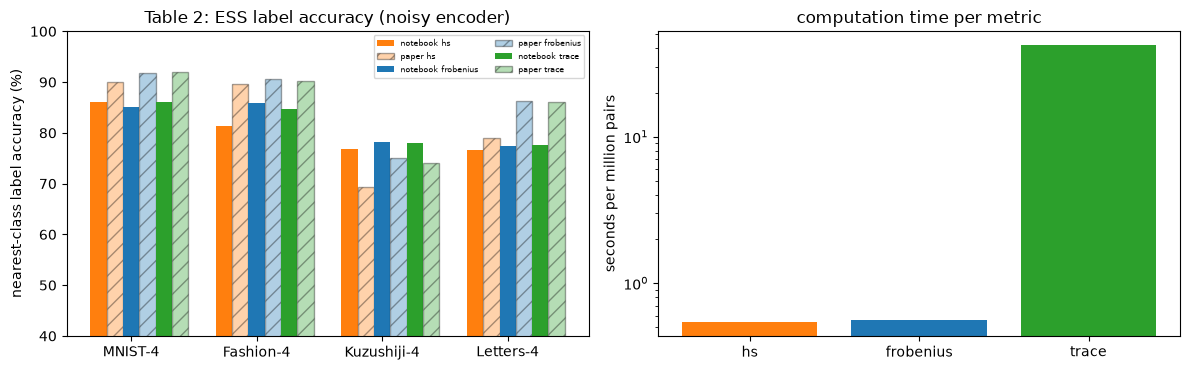

In [10]:
PAPER_T2 = {  # accuracy (%) of min-distance labels, Table 2 ("noisy"): metric -> task -> value
    "hs":        {"MNIST-4": 90.0, "Fashion-4": 89.6, "Kuzushiji-4": 69.3, "Letters-4": 79.0},
    "frobenius": {"MNIST-4": 91.7, "Fashion-4": 90.7, "Kuzushiji-4": 75.0, "Letters-4": 86.3},
    "trace":     {"MNIST-4": 92.0, "Fashion-4": 90.3, "Kuzushiji-4": 74.0, "Letters-4": 86.0}}
PAPER_T2_TIME = {"hs": 7.4, "frobenius": 2.2, "trace": 9.8}
METRICS = ["hs", "frobenius", "trace"]

def ess_accuracy(task_name, noise, seed, n_total=N_ESS, metrics=METRICS, n_classes=None, n_feat=N_FEATURES, enc_kwargs=None):
    """Draw n_total samples, half reference (true labels) / half evaluated; return {metric: (accuracy %, seconds)}."""
    src, cls = TASKS[task_name] if isinstance(task_name, str) else task_name
    ftr, fte, ytr, yte = make_task(*IMAGES[src], cls, n_total, seed, n_feat=n_feat, test_frac=0.5)
    kw = enc_kwargs or dict(seq=ENC_SEQ, use_h=ENC_H)
    n = N_QUBITS
    ea, eb = Enc(ftr, n, noise, **kw), Enc(fte, n, noise, **kw)
    out = {}
    for m in metrics:
        sub = np.arange(len(yte))
        if m == "trace" and ESS_TRACE_EVAL: sub = np.random.default_rng(seed).choice(len(yte), ESS_TRACE_EVAL, replace=False)
        t = time.time(); lab = ess_labels(eb.take(sub), ea, ytr, list(range(len(cls))), m)
        out[m] = (100 * float((lab == yte[sub]).mean()), (time.time() - t) / (len(sub) * len(ytr)) * 1e6)   # accuracy %, seconds per million pairs
    return out

rows = []
for tname in TASKS:
    for noise in (PaperNoise(0.0), PaperNoise(P_NOISE)):
        for sd in ESS_SEEDS:
            for m, (acc, sec) in ess_accuracy(tname, noise, sd).items():
                rows.append(dict(task=tname, p=noise.p, seed=sd, metric=m, acc=acc, sec=sec))
ess = pd.DataFrame(rows)
tab2 = ess[ess.p == P_NOISE].pivot_table(index="metric", columns="task", values="acc", aggfunc="mean").loc[METRICS, list(TASKS)]
tab2_free = ess[ess.p == 0.0].pivot_table(index="metric", columns="task", values="acc", aggfunc="mean").loc[METRICS, list(TASKS)]
tsec = ess[ess.p == P_NOISE].groupby("metric").sec.mean().loc[METRICS]
paper_tab2 = pd.DataFrame(PAPER_T2).T.loc[METRICS, list(TASKS)]
print("ESS accuracy (%), NOISY encoder p = 0.05 -- this notebook (mean over", len(ESS_SEEDS), "draws):"); print(tab2.round(1).to_string())
print("\nESS accuracy (%), noiseless encoder:"); print(tab2_free.round(1).to_string())
print("\nPaper, Table 2:"); print(paper_tab2.to_string())
print("\nSeconds per million state pairs (this machine) and relative to Frobenius; paper: HS 7.4, Frobenius 2.2, Trace 9.8 s -> ratios 3.4 / 1 / 4.5")
print(pd.DataFrame({"sec": tsec, "ratio_to_frobenius": tsec / tsec["frobenius"]}).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.13; xs = np.arange(len(TASKS)); cols = ["tab:orange", "tab:blue", "tab:green"]
for k, m in enumerate(METRICS):
    ax[0].bar(xs + (2 * k - 2.5) * w + w / 2, tab2.loc[m].values, w, color=cols[k], label=f"notebook {m}")
    ax[0].bar(xs + (2 * k - 1.5) * w + w / 2, paper_tab2.loc[m].values, w, color=cols[k], alpha=0.35, hatch="//", edgecolor="k", label=f"paper {m}")
ax[0].set_xticks(xs); ax[0].set_xticklabels(list(TASKS)); ax[0].set_ylabel("nearest-class label accuracy (%)"); ax[0].set_ylim(40, 100)
ax[0].set_title("Table 2: ESS label accuracy (noisy encoder)"); ax[0].legend(fontsize=6, ncol=2)
ax[1].bar(METRICS, [tsec[m] for m in METRICS], color=["tab:orange", "tab:blue", "tab:green"]); ax[1].set_ylabel("seconds per million pairs"); ax[1].set_yscale("log")
ax[1].set_title("computation time per metric"); plt.tight_layout(); plt.show()

### 3.2 Fig. 3: ten classes, 8 latent numbers

Fig. 3 of the paper repeats the measurement on a reduced **MNIST-10** (all ten digits, $d = 8$, 50 % of the data evaluated), noiseless and noisy.

Fig. 3 (reduced MNIST-10, d = 8): min-distance label accuracy (%)
this notebook:
p          0.00  0.05
metric               
hs         63.8  61.7
frobenius  66.0  66.8
trace      66.0  66.2
paper:
            0.00   0.05
hs         91.00  82.67
frobenius  92.00  86.00
trace      91.83  86.00


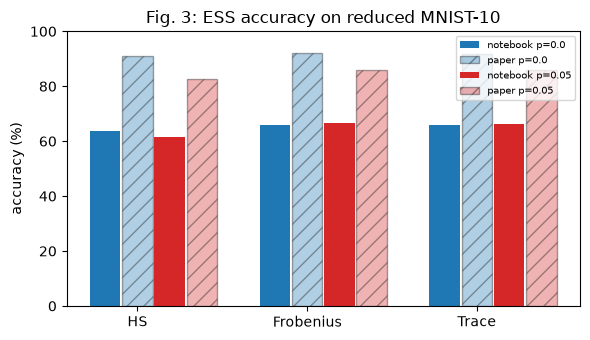

In [11]:
MNIST10 = ("mnist", list(range(10)))
fig3 = []
for noise in (PaperNoise(0.0), PaperNoise(P_NOISE)):
    for sd in ESS_SEEDS:
        for m, (acc, sec) in ess_accuracy(MNIST10, noise, sd).items():
            fig3.append(dict(p=noise.p, seed=sd, metric=m, acc=acc))
fig3 = pd.DataFrame(fig3).groupby(["p", "metric"]).acc.mean().unstack("p").loc[METRICS]
PAPER_F3 = pd.DataFrame({0.0: {"hs": 91.0, "frobenius": 92.0, "trace": 91.83}, P_NOISE: {"hs": 82.67, "frobenius": 86.0, "trace": 86.0}}).loc[METRICS]
print("Fig. 3 (reduced MNIST-10, d = 8): min-distance label accuracy (%)")
print("this notebook:"); print(fig3.round(1).to_string()); print("paper:"); print(PAPER_F3.to_string())
fig, ax = plt.subplots(figsize=(6, 3.5)); xs = np.arange(3)
for k, (p, c) in enumerate([(0.0, "tab:blue"), (P_NOISE, "tab:red")]):
    ax.bar(xs + k * 0.38 - 0.19, fig3[p].values, 0.18, color=c, label=f"notebook p={p}")
    ax.bar(xs + k * 0.38 + 0.0, PAPER_F3[p].values, 0.18, color=c, alpha=0.35, hatch="//", edgecolor="k", label=f"paper p={p}")
ax.set_xticks(xs); ax.set_xticklabels(["HS", "Frobenius", "Trace"]); ax.set_ylim(0, 100); ax.set_ylabel("accuracy (%)")
ax.set_title("Fig. 3: ESS accuracy on reduced MNIST-10"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.3 Fig. 4: angle encoding or amplitude encoding?

Fig. 4 compares two encoders on MNIST-10 with $d = 16$ latent numbers and four noise levels $p$:
* **angle encoding** with four rotations per qubit ($R_Z, R_X, R_Z, R_X$ in the paper; here the order chosen in Section 2.2) on 4 qubits, 16 gates in total;
* **amplitude encoding** of the 16 numbers into the amplitudes of a 4-qubit state. Under noise the state-preparation circuit must be compiled into gates;
  we take PennyLane's `MottonenStatePreparation` decomposition (15 $R_Y$ and 14 CNOT gates, identical structure for every sample, only the angles differ),
  and put the same noise after every gate. # CHOICE: the 16 features are min-max scaled to $[0,\pi]$ (so they are non-negative) and L2-normalised.
* **amplitude encoding as a single operation.** PennyLane's `default.mixed` accepts `AmplitudeEmbedding` as one state-preparation operation without decomposing it; if the paper inserted its noise after
  every *operation*, the amplitude encoder would suffer one noise layer instead of 29 noisy gates. The paper does not say which it did, so we show both variants.

The paper's text says amplitude encoding is *worse* without noise and better under noise; the four numbers per series printed in the figure are
(62.17, 49.0, 46.5, 45.17) and (79.83, 88.83, 88.13, 87.67). Read in the legend order (angle first), angle encoding falls with noise, which matches the paper's explanation, but then amplitude
encoding would also be *better* without noise, contradicting the text. We take the legend order and record the ambiguity.

Fig. 4 (MNIST-10, d = 16, Frobenius ESS accuracy %), columns = noise p
this notebook:
p                               0.00  0.05  0.10  0.20
encoding                                              
angle                           53.6  50.9  48.9  45.8
amplitude (compiled gates)      70.8  58.8  31.4  21.8
amplitude (one prep operation)  70.8  70.6  70.1  68.0
paper (series read in legend order):
           0.00  0.05  0.10  0.20
angle      62.2  49.0  46.5  45.2
amplitude  79.8  88.8  88.1  87.7


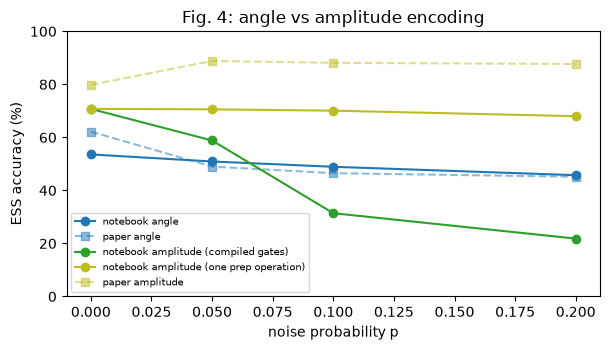

In [12]:
def amplitude_prep_structure(states):
    """Gate structure and per-sample angles of PennyLane's Mottonen state preparation for real non-negative 16-vectors."""
    seqs = [qml.MottonenStatePreparation(s, wires=range(4)).decomposition() for s in states]
    structure = [(op.name, tuple(int(w) for w in op.wires)) for op in seqs[0]]
    assert all([(op.name, tuple(int(w) for w in op.wires)) for op in sq] == structure for sq in seqs[:20]), "gate structure differs between samples"
    angles = np.array([[float(op.parameters[0]) if op.parameters else 0.0 for op in sq] for sq in seqs])
    return structure, angles

def run_amplitude_prep(structure, angles, noise, n=4):
    N = angles.shape[0]; D = 2 ** n
    rho = np.zeros((N, D, D), dtype=complex); rho[:, 0, 0] = 1
    idx = np.arange(D)
    for g, (name, wires) in enumerate(structure):
        if name == "RY":
            S = superop_unitary(ry_mat(angles[:, g]))                     # (N,4,4): one rotation angle per sample
            if noise.S("ry") is not None: S = noise.S("ry") @ S
            rho = full_apply_S(rho, S, wires[0], n)
        elif name == "CNOT":
            c, t = wires
            perm = np.where((idx >> (n - 1 - c)) & 1, idx ^ (1 << (n - 1 - t)), idx)
            rho = rho[:, perm][:, :, perm]
            if noise.S("cnot") is not None:
                for q in wires: rho = full_apply_S(rho, noise.S("cnot"), q, n)
        else:
            raise ValueError(name)
    return rho

class FullEnc:
    """Encoded states given directly as full density matrices (used for amplitude encoding)."""
    def __init__(self, rho, n): self._full, self.n = rho, n
    def full(self): return self._full
    def take(self, idx): return FullEnc(self._full[idx], self.n)

fig4_rows = []
cls16 = list(range(10))
for sd in ESS_SEEDS:
    ftr, fte, ytr, yte = make_task(*IMAGES["mnist"], cls16, N_ESS, sd, n_feat=16, test_frac=0.5)
    # amplitude encoding: scale to [0,pi] (done), L2-normalise
    A_tr = ftr / np.linalg.norm(ftr, axis=1, keepdims=True); A_te = fte / np.linalg.norm(fte, axis=1, keepdims=True)
    st, ang_tr = amplitude_prep_structure(A_tr); _, ang_te = amplitude_prep_structure(A_te)
    for p in NOISE_LEVELS_FIG4:
        noise = PaperNoise(p)
        # angle encoding: 4 rotations per qubit, 16 numbers
        seq4 = (ENC_SEQ * 2)
        ea, eb = Enc(ftr, 4, noise, seq4, ENC_H), Enc(fte, 4, noise, seq4, ENC_H)
        lab = ess_labels(eb, ea, ytr, cls16, "frobenius"); fig4_rows.append(dict(seed=sd, p=p, encoding="angle", acc=100 * (lab == yte).mean()))
        ra, rb = FullEnc(run_amplitude_prep(st, ang_tr, noise), 4), FullEnc(run_amplitude_prep(st, ang_te, noise), 4)
        if p == 0: assert np.allclose(np.einsum("nii->ni", rb.full()).real, A_te ** 2, atol=1e-9), "amplitude preparation is wrong"
        # Frobenius distance on explicit matrices
        def fro(A, B): return np.sqrt(np.maximum((np.abs(A.reshape(len(A), -1)) ** 2).sum(1)[:, None] + (np.abs(B.reshape(len(B), -1)) ** 2).sum(1)[None, :]
                                                 - 2 * (A.reshape(len(A), -1).conj() @ B.reshape(len(B), -1).T).real, 0))
        d = fro(rb.full(), ra.full()); lab = np.array(cls16)[np.stack([d[:, ytr == c].mean(1) for c in cls16], 1).argmin(1)]
        fig4_rows.append(dict(seed=sd, p=p, encoding="amplitude (compiled gates)", acc=100 * (lab == yte).mean()))
        # variant: the state is prepared exactly as ONE operation, followed by a single noise layer on every qubit
        def prep_op(A):
            psi = A.astype(complex); rho = np.einsum("ni,nj->nij", psi, psi.conj())
            if noise.S("prep") is not None:
                for q in range(4): rho = full_apply_S(rho, noise.S("prep"), q, 4)
            return rho
        d2 = fro(prep_op(A_te), prep_op(A_tr)); lab = np.array(cls16)[np.stack([d2[:, ytr == c].mean(1) for c in cls16], 1).argmin(1)]
        fig4_rows.append(dict(seed=sd, p=p, encoding="amplitude (one prep operation)", acc=100 * (lab == yte).mean()))
fig4 = pd.DataFrame(fig4_rows).groupby(["encoding", "p"]).acc.mean().unstack("p")
PAPER_F4 = pd.DataFrame({"angle": [62.17, 49.0, 46.5, 45.17], "amplitude": [79.83, 88.83, 88.13, 87.67]}, index=NOISE_LEVELS_FIG4).T
fig4 = fig4.loc[["angle", "amplitude (compiled gates)", "amplitude (one prep operation)"]]
print("Fig. 4 (MNIST-10, d = 16, Frobenius ESS accuracy %), columns = noise p")
print("this notebook:"); print(fig4.round(1).to_string()); print("paper (series read in legend order):"); print(PAPER_F4.round(1).to_string())
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for enc_, pap, c in [("angle", "angle", "tab:blue"), ("amplitude (compiled gates)", "amplitude", "tab:green"), ("amplitude (one prep operation)", "amplitude", "tab:olive")]:
    ax.plot(NOISE_LEVELS_FIG4, fig4.loc[enc_].values, "o-", color=c, label=f"notebook {enc_}")
    if enc_ != "amplitude (compiled gates)": ax.plot(NOISE_LEVELS_FIG4, PAPER_F4.loc[pap].values, "s--", color=c, alpha=0.5, label=f"paper {pap}")
ax.set_xlabel("noise probability p"); ax.set_ylabel("ESS accuracy (%)"); ax.set_ylim(0, 100); ax.legend(fontsize=7); ax.set_title("Fig. 4: angle vs amplitude encoding")
plt.tight_layout(); plt.show()

### 3.4 What QUID does to the labels

Take the MNIST-4 task, poison half of the training set with QUID and look at what the adversary writes: for each true class, which
label does QUID assign? A good attack should almost never reproduce the true label, and should concentrate the wrong labels on the class that is
farthest in Hilbert space, so that the victim sees a *consistent* but wrong story rather than random noise.

poisoned samples: 350 of 700 (eps = 0.5); QUID label equals the true label for 0.6 % of them
mean Frobenius distance from a poisoned sample to each clean class (rows: true class):
       0      1      2      3
0  0.685  0.847  0.829  0.810
1  0.831  0.426  0.730  0.718
2  0.816  0.710  0.643  0.750
3  0.792  0.713  0.754  0.617


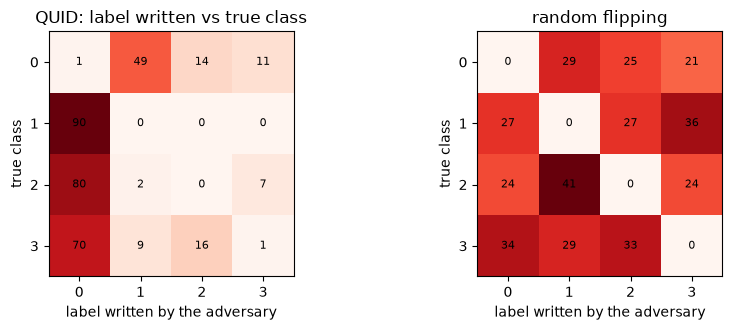

In [13]:
tk = get_task("MNIST-4", SEED); noise = PaperNoise(P_NOISE)
enc_tr = Enc(tk["ftr"], N_QUBITS, noise, ENC_SEQ, ENC_H)
N = len(tk["ytr"]); pidx = np.random.default_rng(SEED).permutation(N)[:N // 2]; cidx = np.setdiff1d(np.arange(N), pidx)
y_quid = quid_labels(enc_tr.take(pidx), enc_tr.take(cidx), tk["ytr"][cidx], tk["classes"])
y_rand = random_flip(tk["ytr"], pidx, tk["classes"], np.random.default_rng(SEED))[pidx]
conf = pd.crosstab(pd.Series(tk["ytr"][pidx], name="true class"), pd.Series(y_quid, name="QUID label"))
conf_r = pd.crosstab(pd.Series(tk["ytr"][pidx], name="true class"), pd.Series(y_rand, name="random label"))
print(f"poisoned samples: {len(pidx)} of {N} (eps = 0.5); QUID label equals the true label for {100*np.mean(y_quid == tk['ytr'][pidx]):.1f} % of them")
dm = class_mean_distance(enc_tr.take(pidx), enc_tr.take(cidx), tk["ytr"][cidx], tk["classes"], "frobenius")
print("mean Frobenius distance from a poisoned sample to each clean class (rows: true class):")
print(pd.DataFrame(dm).groupby(tk["ytr"][pidx]).mean().round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, tab, ttl in [(ax[0], conf, "QUID: label written vs true class"), (ax[1], conf_r, "random flipping")]:
    im = a.imshow(tab.values, cmap="Reds"); a.set_xticks(range(4)); a.set_yticks(range(4)); a.set_xlabel("label written by the adversary"); a.set_ylabel("true class"); a.set_title(ttl)
    for i in range(4):
        for j in range(4): a.text(j, i, int(tab.values[i, j]), ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## 4. The victim: a hybrid QNN, its training, and classical baselines

The model is trained as the paper describes: Adam, learning rate 0.01, batch size 32, 30 epochs, cross-entropy. The paper computes the circuit gradient with
**SPSA** (simultaneous perturbation stochastic approximation), because backpropagation is not available on real quantum hardware. SPSA moves all circuit
parameters at once by $\pm c$ with random signs $\Delta_i$, evaluates the loss twice, and uses
$g_i \approx \frac{L(\theta + c\Delta) - L(\theta - c\Delta)}{2c}\,\Delta_i$ as a noisy gradient. The classical linear layer is trained with its exact gradient.

Below: one picture of the circuit, then the clean model and three classical models on the same eight numbers. Every
training run in this notebook uses the seeds in the configuration cell, and the QNN and the classical models see the **same** training split.

In [14]:
# draw the 4-qubit hybrid QNN (encoding + PQC-1) with PennyLane, for orientation
dev_draw = qml.device("default.qubit", wires=4)
@qml.qnode(dev_draw)
def draw_circuit(x, th):
    if ENC_H:
        for q in range(4): qml.Hadamard(q)
    for k, g in enumerate(ENC_SEQ):
        for q in range(4): (qml.RX if g == "rx" else qml.RZ)(x[k * 4 + q], wires=q)
    qml.Barrier(wires=range(4))
    for q in range(4): qml.RX(th[2 * q], wires=q); qml.RZ(th[2 * q + 1], wires=q)
    return [qml.expval(qml.PauliZ(q)) for q in range(4)]
print(qml.draw(draw_circuit, decimals=2)(np.linspace(0.3, 2.9, 8), np.linspace(0.4, 5.9, 8)))
print("\nPQC-8 and PQC-6 add controlled-RX gates between the rotation layers; <Z> of every qubit feeds a linear layer with one output per class.")

0: ──RX(0.30)──RZ(1.79)─╭||──RX(0.40)──RZ(1.19)─┤  <Z>
1: ──RX(0.67)──RZ(2.16)─├||──RX(1.97)──RZ(2.76)─┤  <Z>
2: ──RX(1.04)──RZ(2.53)─├||──RX(3.54)──RZ(4.33)─┤  <Z>
3: ──RX(1.41)──RZ(2.90)─╰||──RX(5.11)──RZ(5.90)─┤  <Z>

PQC-8 and PQC-6 add controlled-RX gates between the rotation layers; <Z> of every qubit feeds a linear layer with one output per class.


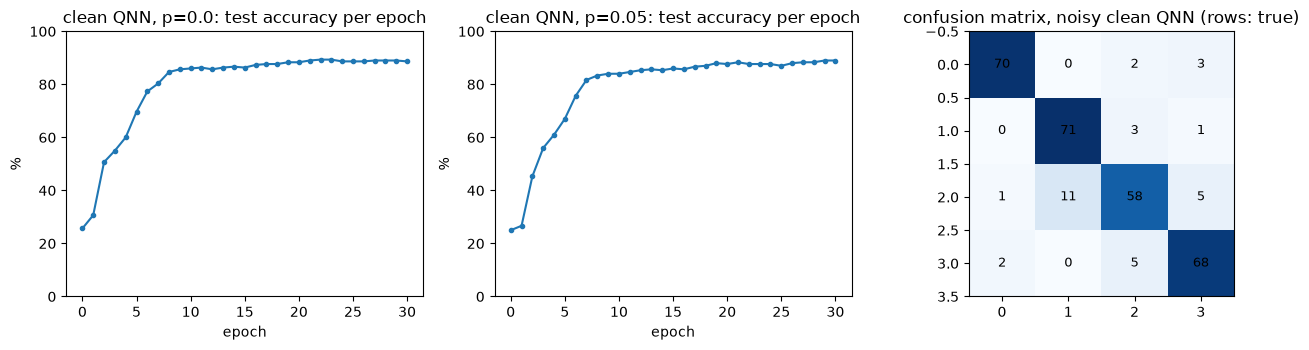

                    model  test_acc  seconds
 hybrid QNN PQC-1 (p=0.0)     88.67     1.22
hybrid QNN PQC-1 (p=0.05)     89.00     1.20
                  SVC-rbf     95.67     0.25
             RandomForest     93.67     0.25
                   LogReg     91.33     0.25


In [15]:
def classical_scores(tk, y_train, seed):
    """SVC(rbf), random forest and logistic regression on the same 8 scaled numbers, trained with labels y_train; returns test accuracies (%)."""
    out = {}
    for name, mdl in [("SVC-rbf", SVC(random_state=seed)), ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=seed)),
                      ("LogReg", LogisticRegression(max_iter=2000))]:
        out[name] = 100 * float(mdl.fit(tk["ftr"], y_train).score(tk["fte"], tk["yte"]))
    return out

def confusion(y, p, C):
    M = np.zeros((C, C), dtype=int)
    for a, b in zip(y, p): M[a, b] += 1
    return M

tk = get_task("MNIST-4", SEED); rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, noise in zip(axes[:2], (PaperNoise(0.0), PaperNoise(P_NOISE))):
    etr, ete = Enc(tk["ftr"], 4, noise, ENC_SEQ, ENC_H), Enc(tk["fte"], 4, noise, ENC_SEQ, ENC_H)
    m = QNN("PQC-1", 4, 4, noise, rng=np.random.default_rng(SEED)); t = time.time()
    h = train_qnn(m, etr, tk["ytr"], ete, tk["yte"], EPOCHS, LR, BATCH, SEED); pred = m.predict(ete); sec = time.time() - t
    rows.append(dict(model=f"hybrid QNN PQC-1 ({noise.name})", test_acc=100 * np.mean(pred == tk["yte"]), seconds=sec))
    ax.plot(h["epoch"], np.array(h["test_acc"]) * 100, "o-", ms=3); ax.set_title(f"clean QNN, {noise.name}: test accuracy per epoch"); ax.set_xlabel("epoch"); ax.set_ylabel("%"); ax.set_ylim(0, 100)
    last = confusion(tk["yte"], pred, 4)
im = axes[2].imshow(last, cmap="Blues"); axes[2].set_title("confusion matrix, noisy clean QNN (rows: true)")
for i in range(4):
    for j in range(4): axes[2].text(j, i, last[i, j], ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()
t = time.time(); cs = classical_scores(tk, tk["ytr"], SEED); sec = time.time() - t
rows += [dict(model=k, test_acc=v, seconds=sec / 3) for k, v in cs.items()]
print(pd.DataFrame(rows).round(2).to_string(index=False))

## 5. The poisoning experiments

All experiments share one engine, `run_one`. For a task, circuit, noise setting, poison ratio $\varepsilon$ and method it
1. draws the dataset (class-balanced, 700 / 300 split) with the repetition's seed;
2. picks a random subset of $\varepsilon \cdot 700$ training samples to poison (the **same** subset for random flipping and QUID in a given repetition, so the comparison is paired);
3. writes the poisoned labels: *random* = a random other class; *QUID* = the farthest class in Hilbert space under the **same noise** as the victim (the adversary runs the noisy encoding circuit, Sec. 3.3);
   for *bi-level* poisoning the poisoned samples first get random features, drawn uniformly in $[0,\pi]^8$, and QUID labels are computed for those random features;
4. trains the victim from random weights on the poisoned set and scores the **final epoch** on the clean test set. # CHOICE: the paper does not say whether the last or the best epoch is reported; the last one needs no test-set peeking.

Results are cached by their full parameter set, so tables that overlap (Table 4 and Table 6 at $\varepsilon = 0.5$) use the very same runs.

In [16]:
RESULTS = {}
DEVICE_NOISE = {}                      # filled in section 5.4
_ENC_CACHE = {}

def make_noise(spec):
    kind, v = spec
    return PaperNoise(v) if kind == "paper" else DEVICE_NOISE[v]

def encoded(X_key, X, n, noise, kind):
    key = (X_key, n, noise.name, kind)
    if key not in _ENC_CACHE: _ENC_CACHE[key] = Enc(X, n, noise, ENC_SEQ, ENC_H)
    return _ENC_CACHE[key]

def build_poisoned(tk, noise, eps, method, seed, bilevel=False, n=4):
    """Return (X_train, y_train_poisoned, enc_train, poison_idx)."""
    N = len(tk["ytr"]); classes = tk["classes"]
    npois = int(round(eps * N)) if method != "clean" else 0
    pidx = np.random.default_rng(10_000 + seed).permutation(N)[:npois]; cidx = np.setdiff1d(np.arange(N), pidx)
    X = tk["ftr"].copy(); y = tk["ytr"].copy()
    if bilevel and npois: X[pidx] = np.random.default_rng(30_000 + seed).uniform(0, np.pi, (npois, X.shape[1]))
    enc = Enc(X, n, noise, ENC_SEQ, ENC_H) if (bilevel and npois) else encoded((tk["name"], seed, "train"), X, n, noise, "clean-train")
    if npois:
        if method == "quid":
            y[pidx] = quid_labels(enc.take(pidx), enc.take(cidx), tk["ytr"][cidx], classes)
        elif bilevel:
            y[pidx] = np.random.default_rng(20_000 + seed).choice(classes, npois)               # random features get random labels
        else:
            y[pidx] = random_flip(tk["ytr"], pidx, classes, np.random.default_rng(20_000 + seed))[pidx]
    return X, y, enc, pidx

def run_one(tname, pqc, noise_spec, eps, method, seed, bilevel=False, epochs=None, classical=False):
    key = (tname, pqc, noise_spec, eps, method, seed, bilevel, epochs)
    tk = get_task(tname, seed)
    if key not in RESULTS:
        ep = epochs or (EPOCHS if pqc == "PQC-1" else EPOCHS_DEEP); noise = make_noise(noise_spec)
        X, y, enc_tr, pidx = build_poisoned(tk, noise, eps, method, seed, bilevel)
        enc_te = encoded((tname, seed, "test"), tk["fte"], 4, noise, "test")
        model = QNN(pqc, 4, len(tk["classes"]), noise, rng=np.random.default_rng(seed))
        t = time.time(); h = train_qnn(model, enc_tr, y, enc_te, tk["yte"], ep, LR, BATCH, seed)
        RESULTS[key] = dict(acc=100 * h["test_acc"][-1], loss=h["test_loss"][-1], curve=h["test_acc"], loss_curve=h["test_loss"], seconds=time.time() - t,
                            label_correct=float((y[pidx] == tk["ytr"][pidx]).mean()) if len(pidx) else np.nan, y_train=y)
    res = RESULTS[key]
    if classical and "SVC-rbf" not in res: res.update(classical_scores(tk, res["y_train"], seed))     # the same (poisoned) labels as the QNN
    return res
def collect(tname, pqc, noise_spec, eps, method, seeds, bilevel=False, key="acc", classical=False):
    return np.array([run_one(tname, pqc, noise_spec, eps, method, s, bilevel, classical=classical or key in ("SVC-rbf", "RandomForest", "LogReg"))[key] for s in seeds])

def pm(a, nd=1): return f"{np.mean(a):.{nd}f} +- {np.std(a):.{nd}f}"

CLAIMS = []         # (source, description, paper value, notebook value, kind) numeric claims
QCLAIMS = []        # (source, description, holds?, detail) qualitative claims
def claim(source, desc, paper, nb, kind):
    """kind: 'acc' = a plain accuracy (higher is better for the claim); 'attack' = accuracy under attack (lower = stronger attack)."""
    CLAIMS.append(dict(source=source, claim=desc, paper=paper, notebook=nb, kind=kind))
def qclaim(source, desc, holds, detail=""):
    QCLAIMS.append(dict(source=source, claim=desc, verdict="reproduced" if holds else "not reproduced", detail=detail))
print("engine ready")

engine ready


### 5.1 Table 4: QUID versus random flipping, noiseless and noisy, poison ratio 0.5

Half of the training labels are poisoned. The victim is PQC-1, trained without noise and with the paper's noise $p = 0.05$ (the adversary's encoder runs in the same noise).
In the noiseless setting the classical models are trained on the same poisoned labels as well.

Test accuracy (%), mean +- std over 5 repetitions, eps = 0.5, PQC-1   [243 s]
                baseline rand_noiseless quid_noiseless baseline_noisy   rand_noisy   quid_noisy
task                                                                                           
MNIST-4      88.7 +- 2.1    84.1 +- 3.4    38.5 +- 5.7    88.3 +- 1.9  83.4 +- 2.0  36.9 +- 1.9
Fashion-4    91.5 +- 2.0    87.5 +- 3.5    45.8 +- 2.8    90.8 +- 2.3  87.8 +- 3.5  48.5 +- 4.7
Kuzushiji-4  77.9 +- 1.8    72.3 +- 4.9    44.1 +- 3.1    77.0 +- 2.3  70.9 +- 4.4  43.4 +- 5.5
Letters-4    71.5 +- 4.0    66.5 +- 2.2    25.5 +- 5.8    71.3 +- 3.8  66.7 +- 2.2  24.7 +- 6.4

Paper, Table 4 (baseline / random / QUID noiseless ; random / QUID noisy):
             baseline  rand_noiseless  quid_noiseless  rand_noisy  quid_noisy
MNIST-4          94.3            91.6            43.9        89.9        31.6
Fashion-4        85.0            83.3            31.9        82.9         7.9
Kuzushiji-4      81.3            74.

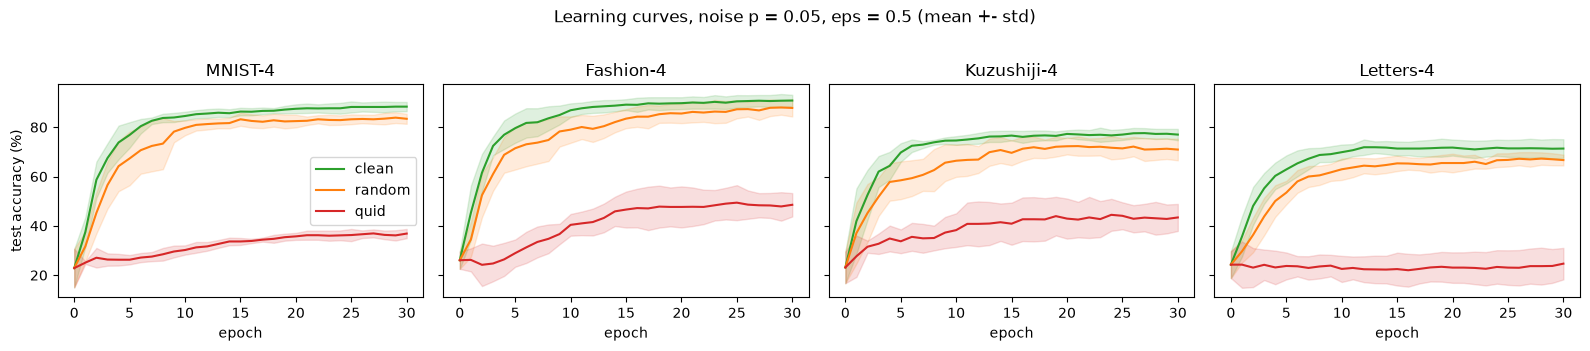

In [17]:
PAPER_T4 = {  # (baseline, random noiseless, QUID noiseless, random noisy, QUID noisy)
    "MNIST-4": (94.3, 91.6, 43.9, 89.9, 31.6), "Fashion-4": (85.0, 83.3, 31.9, 82.9, 7.9),
    "Kuzushiji-4": (81.3, 74.6, 37.0, 72.0, 27.3), "Letters-4": (88.9, 77.9, 30.0, 75.6, 12.6)}
t0 = time.time(); rows = []
for tname in TASKS:
    nl, ny = ("paper", 0.0), ("paper", P_NOISE)
    base = collect(tname, "PQC-1", nl, 0.0, "clean", SEEDS, classical=True)
    row = dict(task=tname, baseline=pm(base),
               rand_noiseless=pm(collect(tname, "PQC-1", nl, 0.5, "random", SEEDS, classical=True)), quid_noiseless=pm(collect(tname, "PQC-1", nl, 0.5, "quid", SEEDS, classical=True)),
               baseline_noisy=pm(collect(tname, "PQC-1", ny, 0.0, "clean", SEEDS)),
               rand_noisy=pm(collect(tname, "PQC-1", ny, 0.5, "random", SEEDS)), quid_noisy=pm(collect(tname, "PQC-1", ny, 0.5, "quid", SEEDS)))
    rows.append(row)
    pb, pr, pq, pr2, pq2 = PAPER_T4[tname]
    claim("Table 4", f"{tname} baseline (noiseless)", pb, np.mean(base), "acc")
    claim("Table 4", f"{tname} random flip, noiseless", pr, np.mean(collect(tname, "PQC-1", nl, 0.5, "random", SEEDS)), "acc")
    claim("Table 4", f"{tname} QUID, noiseless", pq, np.mean(collect(tname, "PQC-1", nl, 0.5, "quid", SEEDS)), "attack")
    claim("Table 4", f"{tname} random flip, noisy p=0.05", pr2, np.mean(collect(tname, "PQC-1", ny, 0.5, "random", SEEDS)), "acc")
    claim("Table 4", f"{tname} QUID, noisy p=0.05", pq2, np.mean(collect(tname, "PQC-1", ny, 0.5, "quid", SEEDS)), "attack")
t4 = pd.DataFrame(rows).set_index("task")
print(f"Test accuracy (%), mean +- std over {len(SEEDS)} repetitions, eps = 0.5, PQC-1   [{time.time()-t0:.0f} s]")
print(t4.to_string())
print("\nPaper, Table 4 (baseline / random / QUID noiseless ; random / QUID noisy):")
print(pd.DataFrame(PAPER_T4, index=["baseline", "rand_noiseless", "quid_noiseless", "rand_noisy", "quid_noisy"]).T.to_string())

# qualitative claims
mean_ = lambda tn, nz, eps, me: np.mean(collect(tn, "PQC-1", ("paper", nz), eps, me, SEEDS))
ordering = {tn: (mean_(tn, 0.0, 0.5, "quid") < mean_(tn, 0.0, 0.5, "random") < mean_(tn, 0.0, 0.0, "clean")) for tn in TASKS}
ordering2 = {tn: (mean_(tn, P_NOISE, 0.5, "quid") < mean_(tn, P_NOISE, 0.5, "random") < mean_(tn, P_NOISE, 0.0, "clean")) for tn in TASKS}
qclaim("Table 4", "QUID < random flipping < clean baseline on every dataset (noiseless)", all(ordering.values()), str(ordering))
qclaim("Table 4", "QUID < random flipping < clean baseline on every dataset (noisy)", all(ordering2.values()), str(ordering2))
qd = np.mean([mean_(tn, 0.0, 0.5, "quid") - mean_(tn, P_NOISE, 0.5, "quid") for tn in TASKS])
rd = np.mean([mean_(tn, 0.0, 0.5, "random") - mean_(tn, P_NOISE, 0.5, "random") for tn in TASKS])
qclaim("Table 4", "QUID loses more accuracy under noise than without (paper: up to 24 points more); random flipping only about 2", qd > 2 and qd > rd,
       f"average extra drop under noise: QUID {qd:.1f} points, random {rd:.1f} points (paper: QUID up to 24, random about 2)")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, tname in zip(axes, TASKS):
    for me, c in [("clean", "tab:green"), ("random", "tab:orange"), ("quid", "tab:red")]:
        eps = 0.0 if me == "clean" else 0.5
        cv = np.array([run_one(tname, "PQC-1", ("paper", P_NOISE), eps, me, s)["curve"] for s in SEEDS]) * 100
        ax.plot(range(cv.shape[1]), cv.mean(0), color=c, label=me); ax.fill_between(range(cv.shape[1]), cv.mean(0) - cv.std(0), cv.mean(0) + cv.std(0), color=c, alpha=0.15)
    ax.set_title(tname); ax.set_xlabel("epoch")
axes[0].set_ylabel("test accuracy (%)"); axes[0].legend(); plt.suptitle("Learning curves, noise p = 0.05, eps = 0.5 (mean +- std)", y=1.02); plt.tight_layout(); plt.show()

### 5.2 Table 3: label flipping versus bi-level poisoning (noise $p = 0.1$)

In the bi-level variant the adversary also replaces the poisoned samples by random feature vectors, then labels them (QUID: farthest class of the random state; random: random label).
The paper finds that this makes QUID *less* effective ("adding randomly generated poisoned samples actually leads to better performance").

In [18]:
PAPER_T3 = {  # baseline, LF random, LF QUID, bi-level random, bi-level QUID
    "MNIST-4": (87.3, 76.7, 7.7, 77.3, 10.3), "Fashion-4": (82.3, 75.3, 1.33, 75.0, 47.6),
    "Kuzushiji-4": (73.6, 65.6, 24.3, 70.7, 28.9), "Letters-4": (76.0, 60.6, 5.7, 74.7, 18.3)}
n3 = ("paper", P_NOISE_T3); rows = []; lf_vs_bl = {}
for tname in TASKS:
    b = collect(tname, "PQC-1", n3, 0.0, "clean", SEEDS)
    lr_, lq = collect(tname, "PQC-1", n3, 0.5, "random", SEEDS), collect(tname, "PQC-1", n3, 0.5, "quid", SEEDS)
    br, bq = collect(tname, "PQC-1", n3, 0.5, "random", SEEDS, bilevel=True), collect(tname, "PQC-1", n3, 0.5, "quid", SEEDS, bilevel=True)
    rows.append(dict(task=tname, baseline=pm(b), LF_random=pm(lr_), LF_QUID=pm(lq), bilevel_random=pm(br), bilevel_QUID=pm(bq)))
    for nm, v, pv, kd in [("baseline", b, PAPER_T3[tname][0], "acc"), ("LF random", lr_, PAPER_T3[tname][1], "acc"), ("LF QUID", lq, PAPER_T3[tname][2], "attack"),
                          ("bi-level random", br, PAPER_T3[tname][3], "acc"), ("bi-level QUID", bq, PAPER_T3[tname][4], "attack")]:
        claim("Table 3", f"{tname} {nm} (p=0.1)", pv, v.mean(), kd)
    lf_vs_bl[tname] = bool(lq.mean() < bq.mean())
print(f"Table 3 analogue: p = {P_NOISE_T3}, eps = 0.5, PQC-1, mean +- std over {len(SEEDS)} repetitions"); print(pd.DataFrame(rows).set_index("task").to_string())
print("\nPaper, Table 3:"); print(pd.DataFrame(PAPER_T3, index=["baseline", "LF_random", "LF_QUID", "bilevel_random", "bilevel_QUID"]).T.to_string())
qclaim("Table 3", "Label-flip QUID is more damaging than bi-level QUID (QUID accuracy lower with LF) on every dataset", all(lf_vs_bl.values()), str(lf_vs_bl))

Table 3 analogue: p = 0.1, eps = 0.5, PQC-1, mean +- std over 5 repetitions
                baseline    LF_random      LF_QUID bilevel_random bilevel_QUID
task                                                                          
MNIST-4      87.3 +- 1.5  84.8 +- 4.2  32.9 +- 1.9    83.3 +- 1.5  15.3 +- 3.6
Fashion-4    89.3 +- 2.6  86.3 +- 3.2  52.1 +- 5.9    84.5 +- 1.9  16.5 +- 5.4
Kuzushiji-4  76.1 +- 2.9  69.9 +- 4.5  43.2 +- 7.1    71.4 +- 2.0  12.1 +- 6.7
Letters-4    70.7 +- 3.4  65.8 +- 3.0  21.5 +- 5.8    67.1 +- 3.7   8.7 +- 2.0

Paper, Table 3:
             baseline  LF_random  LF_QUID  bilevel_random  bilevel_QUID
MNIST-4          87.3       76.7     7.70            77.3          10.3
Fashion-4        82.3       75.3     1.33            75.0          47.6
Kuzushiji-4      73.6       65.6    24.30            70.7          28.9
Letters-4        76.0       60.6     5.70            74.7          18.3


### 5.3 Table 6: poison ratio and circuit expressivity

Noise $p = 0.05$. MNIST-4 is trained with PQC-1 (low complexity, no entanglement), PQC-8 (medium) and PQC-6 (high; many noisy gates), the other three datasets with
PQC-1 only, exactly as in the paper. PQC-8 / PQC-6 simulate a full $16\times16$ density matrix per gate and take about 25 s / 60 s per training run on a 2-core CPU, which is why
the number of repetitions and (in `FAST_MODE`) the epochs and the poison-ratio grid are smaller for them.

MNIST-4 PQC-1: done [37 s]


MNIST-4 PQC-8: done [515 s]


MNIST-4 PQC-6: done [1517 s]


Fashion-4 PQC-1: done [1554 s]


Kuzushiji-4 PQC-1: done [1594 s]


Letters-4 PQC-1: done [1630 s]


Table 6 analogue: noise p = 0.05, test accuracy (%), mean +- std
                  eps=0 baseline eps=0.1 rand eps=0.1 QUID eps=0.3 rand eps=0.3 QUID eps=0.5 rand eps=0.5 QUID  eps=0.7 rand eps=0.7 QUID
dataset     PQC                                                                                                                          
MNIST-4     PQC-1    88.3 +- 1.9  88.3 +- 2.6  88.2 +- 2.7  86.0 +- 2.4  80.5 +- 3.6  83.4 +- 2.0  36.9 +- 1.9  42.8 +- 10.5   7.4 +- 1.6
            PQC-8    87.3 +- 0.3  87.8 +- 1.2  86.0 +- 0.3  84.0 +- 0.3  78.3 +- 0.3  80.5 +- 2.5  31.3 +- 2.7   37.5 +- 0.8   8.7 +- 4.0
            PQC-6    83.8 +- 1.8  82.2 +- 5.2  82.2 +- 2.2  78.2 +- 8.8  63.2 +- 2.2  74.7 +- 5.3  28.5 +- 3.5   44.5 +- 9.2   9.0 +- 3.0
Fashion-4   PQC-1    90.8 +- 2.3  90.3 +- 2.3  90.3 +- 2.4  89.5 +- 2.4  82.5 +- 5.5  87.8 +- 3.5  48.5 +- 4.7  46.4 +- 11.0   6.4 +- 2.4
Kuzushiji-4 PQC-1    77.0 +- 2.3  77.1 +- 2.3  77.1 +- 2.0  74.9 +- 2.7  75.2 +- 0.9  70.9 +- 4.4  43.4 +- 

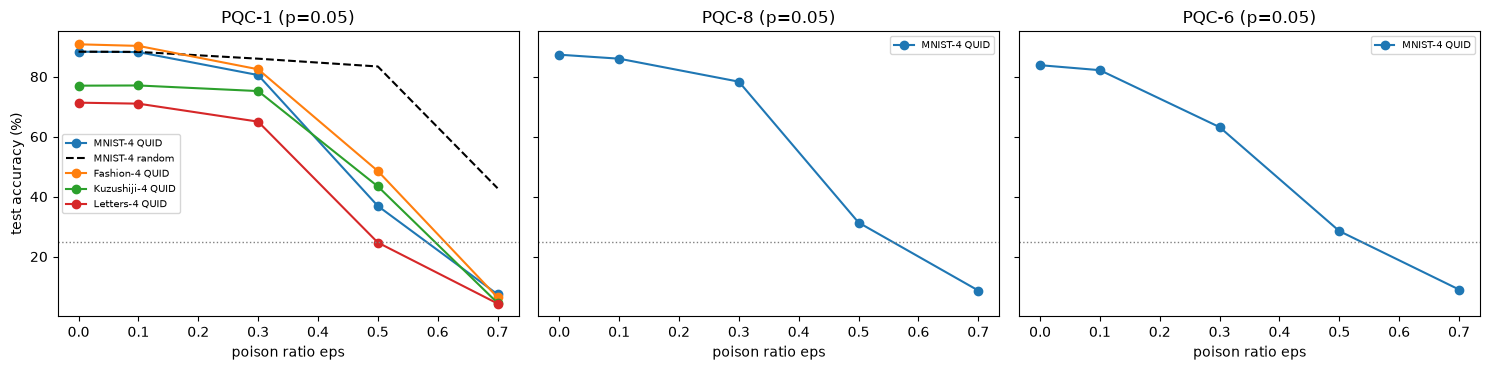

In [19]:
PAPER_T6 = {   # (dataset, circuit): [baseline, (rand, quid) at eps = 0.1, 0.3, 0.5, 0.7]
    ("MNIST-4", "PQC-1"):  [93.3, (93.0, 92.6), (92.3, 82.3), (89.9, 31.6), (53.3, 0.99)],
    ("MNIST-4", "PQC-8"):  [81.3, (80.6, 77.3), (77.6, 69.3), (74.6, 20.9), (40.6, 5.63)],
    ("MNIST-4", "PQC-6"):  [72.6, (54.3, 46.9), (43.3, 21.3), (52.3, 20.9), (33.6, 20.9)],
    ("Fashion-4", "PQC-1"): [87.0, (86.3, 82.9), (87.0, 76.3), (82.9, 7.9), (75.3, 0.66)],
    ("Kuzushiji-4", "PQC-1"): [77.6, (76.3, 27.3), (76.9, 70.6), (72.0, 27.3), (35.3, 0.66)],
    ("Letters-4", "PQC-1"): [84.3, (83.3, 81.6), (81.3, 61.3), (75.6, 12.6), (38.9, 1.99)]}
EPS_ALL = [0.1, 0.3, 0.5, 0.7]
ny = ("paper", P_NOISE); t0 = time.time(); T6 = {}
for (tname, pqc), pv in PAPER_T6.items():
    seeds = SEEDS if pqc == "PQC-1" else SEEDS_DEEP
    grid = EPS_ALL if pqc == "PQC-1" else EPS_GRID_DEEP
    base = collect(tname, pqc, ny, 0.0, "clean", seeds); T6[(tname, pqc)] = {0.0: (base, base)}
    for eps in grid:
        T6[(tname, pqc)][eps] = (collect(tname, pqc, ny, eps, "random", seeds), collect(tname, pqc, ny, eps, "quid", seeds))
    print(f"{tname} {pqc}: done [{time.time()-t0:.0f} s]", flush=True)

rows = []
for (tname, pqc), d in T6.items():
    row = {"dataset": tname, "PQC": pqc, "eps=0 baseline": pm(d[0.0][0])}
    for eps in EPS_ALL:
        row[f"eps={eps} rand"] = pm(d[eps][0]) if eps in d else "-"; row[f"eps={eps} QUID"] = pm(d[eps][1]) if eps in d else "-"
    rows.append(row)
print(f"Table 6 analogue: noise p = {P_NOISE}, test accuracy (%), mean +- std"); print(pd.DataFrame(rows).set_index(["dataset", "PQC"]).to_string())
rows = []
for k, v in PAPER_T6.items():
    row = {"dataset": k[0], "PQC": k[1], "eps=0 baseline": v[0]}
    for eps, (a, b) in zip(EPS_ALL, v[1:]): row[f"eps={eps} rand"] = a; row[f"eps={eps} QUID"] = b
    rows.append(row)
print("\nPaper, Table 6 (the Kuzushiji-4 eps=0.1 QUID entry, 27.3, repeats the eps=0.5 value and looks like a typo):"); print(pd.DataFrame(rows).set_index(["dataset", "PQC"]).to_string())

for (tname, pqc), d in T6.items():
    pv = PAPER_T6[(tname, pqc)]
    claim("Table 6", f"{tname} {pqc} baseline (eps=0)", pv[0], d[0.0][0].mean(), "acc")
    for eps, (pr, pq) in zip(EPS_ALL, pv[1:]):
        if eps in d and not (eps == 0.5 and pqc == "PQC-1"):          # eps = 0.5, PQC-1 is Table 4 (noisy) again
            claim("Table 6", f"{tname} {pqc} eps={eps} random", pr, d[eps][0].mean(), "acc"); claim("Table 6", f"{tname} {pqc} eps={eps} QUID", pq, d[eps][1].mean(), "attack")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, pqc in zip(axes, ["PQC-1", "PQC-8", "PQC-6"]):
    for (tname, p_), d in T6.items():
        if p_ != pqc: continue
        es = sorted(d); ax.plot(es, [d[e][1].mean() for e in es], "o-", label=f"{tname} QUID")
        if pqc == "PQC-1" and tname == "MNIST-4": ax.plot(es, [d[e][0].mean() for e in es], "k--", label="MNIST-4 random")
    ax.axhline(25, color="grey", ls=":", lw=1); ax.set_title(f"{pqc} (p={P_NOISE})"); ax.set_xlabel("poison ratio eps"); ax.legend(fontsize=7)
axes[0].set_ylabel("test accuracy (%)"); plt.tight_layout(); plt.show()

# qualitative claims
d1 = T6[("MNIST-4", "PQC-1")]
qclaim("Table 6", "eps <= 0.1 gives minimal degradation (PQC-1, MNIST-4, QUID within 5 points of the clean model)", d1[0.0][0].mean() - d1[0.1][1].mean() <= 5,
       f"clean {d1[0.0][0].mean():.1f}, QUID eps=0.1 {d1[0.1][1].mean():.1f}")
below = {tn: T6[(tn, "PQC-1")][0.7][1].mean() for tn in TASKS}
qclaim("Table 6", "At eps = 0.7 QUID pushes PQC-1 below chance (25 %) on every dataset", all(v < 25 for v in below.values()), str({k: round(v, 1) for k, v in below.items()}))
if 0.5 in T6[("MNIST-4", "PQC-6")]:
    ref_eps = 0.7 if 0.7 in T6[("MNIST-4", "PQC-6")] else 0.5
    loss1 = T6[("MNIST-4", "PQC-1")][0.0][0].mean() - T6[("MNIST-4", "PQC-1")][ref_eps][1].mean()
    loss6 = T6[("MNIST-4", "PQC-6")][0.0][0].mean() - T6[("MNIST-4", "PQC-6")][ref_eps][1].mean()
    qclaim("Table 6", "QUID is less effective on the deep, noisy PQC-6 than on PQC-1 (smaller accuracy drop at the largest tested eps)", loss6 < loss1,
           f"eps={ref_eps}: drop {loss1:.1f} points for PQC-1, {loss6:.1f} for PQC-6")

### 5.4 Table 5: noise models of IBM_Brisbane and IBM_Kyiv

The paper puts the noise models of two IBM devices into `qiskit.aer`. We use the frozen calibration snapshots shipped with `qiskit-ibm-runtime`
(`FakeBrisbane`, `FakeKyiv`), take qubits 0 to 3, and build our reduced noise model from their calibration data: per $\sqrt{X}$ pulse the
gate error, duration, $T_1$, $T_2$, and the readout error. After transpilation to the device's gate set an $R_X$ costs two $\sqrt{X}$ pulses and $R_Z$ is free. The cell
**cross-checks this reduced model against `qiskit-aer`'s own noise model of the same backend** on random circuits before using it.

Honest expectation: the gate errors of today's IBM devices (a few $10^{-4}$ per pulse) are 100 times smaller than the paper's $p = 0.05$; for this four-qubit, single-qubit-gate circuit
the readout error (1 to 3 %) is the largest effect, so the hardware-noise runs should resemble the *noiseless* ones.

In [20]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane, FakeKyiv

def device_noise_from_backend(backend, name, qubits=(0, 1, 2, 3)):
    t = backend.target
    f = lambda vals: float(np.mean(vals))
    return DeviceNoise(name, f([t["sx"][(q,)].error for q in qubits]), f([t["sx"][(q,)].duration for q in qubits]),
                       f([t.qubit_properties[q].t1 for q in qubits]), f([t.qubit_properties[q].t2 for q in qubits]),
                       f([t["measure"][(q,)].error for q in qubits]))

BACKENDS = {"IBM_Brisbane": FakeBrisbane(), "IBM_Kyiv": FakeKyiv()}
rows = []
r = np.random.default_rng(1); Xd = r.uniform(0, np.pi, (6, 8)); th8 = r.uniform(0, 2 * np.pi, 8)
for name, be in BACKENDS.items():
    dn = device_noise_from_backend(be, name); DEVICE_NOISE[name] = dn
    # our reduced model (no readout in the density matrix) vs qiskit-aer density-matrix simulation with the full backend noise model
    vec = encode_product(Xd, 4, dn, ENC_SEQ, ENC_H)
    th = np.zeros((1, 2, 4)); th[0, 0] = th8[0::2]; th[0, 1] = th8[1::2]
    z_mine = (lambda v: v[..., 0].real - v[..., 3].real)(pqc1_product(vec, th, dn))
    z_free = z_from_product(pqc1_product(encode_product(Xd, 4, PaperNoise(0.0), ENC_SEQ, ENC_H), th, PaperNoise(0.0)))
    sim = AerSimulator(noise_model=NoiseModel.from_backend(be), method="density_matrix"); z_aer = []
    for x in Xd:
        qc = QuantumCircuit(4)
        if ENC_H: [qc.h(q) for q in range(4)]
        for k, g in enumerate(ENC_SEQ):
            for q in range(4): (qc.rx if g == "rx" else qc.rz)(x[k * 4 + q], q)
        for q in range(4): qc.rx(th8[2 * q], q)
        for q in range(4): qc.rz(th8[2 * q + 1], q)
        tq = transpile(qc, basis_gates=["rz", "sx", "x"], optimization_level=0); tq.save_density_matrix()
        rho = np.array(sim.run(tq).result().data()["density_matrix"]); probs = np.diag(rho).real
        bits = (np.arange(16)[:, None] >> np.arange(4)[None, :]) & 1                      # qiskit: qubit q is bit q (little endian)
        z_aer.append(probs @ (1 - 2 * bits))
    z_aer = np.array(z_aer)
    rows.append(dict(device=name, readout_error=dn.readout,
                     max_diff_reduced_vs_aer=np.abs(z_mine - z_aer).max(), max_diff_noiseless_vs_aer=np.abs(z_free - z_aer).max()))
chk = pd.DataFrame(rows)
print("Cross-check of the <Z> values (gate noise only; readout error is added separately):"); print(chk.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("-> the reduced model is closer to qiskit-aer than the noiseless circuit, and the gate noise itself is below 0.005 in <Z>; the readout error is what matters.")

Cross-check of the <Z> values (gate noise only; readout error is added separately):
      device  readout_error  max_diff_reduced_vs_aer  max_diff_noiseless_vs_aer
IBM_Brisbane         0.0242                   0.0009                     0.0040
    IBM_Kyiv         0.0093                   0.0018                     0.0034
-> the reduced model is closer to qiskit-aer than the noiseless circuit, and the gate noise itself is below 0.005 in <Z>; the readout error is what matters.


In [21]:
PAPER_T5 = {  # dataset: (baseline, Brisbane random, Brisbane QUID, Kyiv random, Kyiv QUID)
    "MNIST-4": (83.1, 71.7, 10.3, 73.6, 8.9), "Fashion-4": (80.7, 73.3, 8.7, 73.8, 7.6)}
rows = []; drops = {}
for tname in PAPER_T5:
    pb, pbr, pbq, pkr, pkq = PAPER_T5[tname]
    for dev, (pr, pq) in [("IBM_Brisbane", (pbr, pbq)), ("IBM_Kyiv", (pkr, pkq))]:
        sp = ("device", dev)
        b, rr, qq = collect(tname, "PQC-1", sp, 0.0, "clean", SEEDS), collect(tname, "PQC-1", sp, 0.5, "random", SEEDS), collect(tname, "PQC-1", sp, 0.5, "quid", SEEDS)
        rows.append(dict(dataset=tname, device=dev, baseline=pm(b), random=pm(rr), QUID=pm(qq), paper_baseline=pb, paper_random=pr, paper_QUID=pq))
        claim("Table 5", f"{tname} {dev} baseline", pb, b.mean(), "acc"); claim("Table 5", f"{tname} {dev} random", pr, rr.mean(), "acc"); claim("Table 5", f"{tname} {dev} QUID", pq, qq.mean(), "attack")
        drops[(tname, dev)] = b.mean() - qq.mean()
print(f"Device-noise runs, eps = 0.5, PQC-1, mean +- std over {len(SEEDS)} repetitions (accuracy %):"); print(pd.DataFrame(rows).set_index(["dataset", "device"]).to_string())
qclaim("Table 5", "Under device noise QUID drives accuracy down by about 70 points (paper: 73 Brisbane, 72 Kyiv)", all(v > 50 for v in drops.values()),
       "drops (clean - QUID): " + str({f"{k[0]}/{k[1]}": round(v, 1) for k, v in drops.items()}))

Device-noise runs, eps = 0.5, PQC-1, mean +- std over 5 repetitions (accuracy %):
                           baseline       random         QUID  paper_baseline  paper_random  paper_QUID
dataset   device                                                                                       
MNIST-4   IBM_Brisbane  88.6 +- 2.2  84.3 +- 3.3  38.5 +- 5.6            83.1          71.7        10.3
          IBM_Kyiv      88.7 +- 2.1  84.2 +- 3.4  38.6 +- 5.8            83.1          73.6         8.9
Fashion-4 IBM_Brisbane  91.5 +- 2.1  87.3 +- 3.6  45.7 +- 2.8            80.7          73.3         8.7
          IBM_Kyiv      91.5 +- 2.1  87.4 +- 3.6  45.8 +- 2.8            80.7          73.8         7.6


### 5.5 Table 7: a partition-aggregation defence

The paper tests QUID against SS-DPA (Levine and Feizi, *Deep Partition Aggregation* with semi-supervised learning, $k = 3$). Its building block, **Deep Partition Aggregation (DPA)**, splits the training set into $k$
disjoint partitions, trains one model per partition, and lets them vote: a poisoned sample can corrupt only the one model whose partition it landed in. We implement DPA with $k = 3$ QNNs (about 233 samples each) and
majority voting (ties broken by summed probabilities). # CHOICE: the semi-supervised half of SS-DPA (unlabelled-data consistency training of every base model) is **not** implemented, so the numbers below
are for plain DPA and are not a like-for-like reproduction of the "SS-DPA" columns. Noiseless training, as in the paper.

In [22]:
PAPER_T7 = {  # dataset: (baseline, eps=0.3 w/o def, eps=0.3 SS-DPA, eps=0.5 w/o def, eps=0.5 SS-DPA)
    "MNIST-4": (94.3, 91.0, 91.3, 43.9, 49.3), "Fashion-4": (85.0, 75.0, 75.3, 31.9, 41.0),
    "Kuzushiji-4": (81.3, 73.7, 80.3, 37.0, 40.7), "Letters-4": (88.9, 72.0, 76.7, 30.0, 21.0)}

def run_dpa(tname, noise_spec, eps, method, seed, k=3, epochs=None):
    key = ("dpa", tname, noise_spec, eps, method, seed, k)
    if key in RESULTS: return RESULTS[key]
    epochs = epochs or EPOCHS
    tk = get_task(tname, seed); noise = make_noise(noise_spec)
    X, y, enc_tr, pidx = build_poisoned(tk, noise, eps, method, seed)
    enc_te = encoded((tname, seed, "test"), tk["fte"], 4, noise, "test")
    parts = np.array_split(np.random.default_rng(40_000 + seed).permutation(len(y)), k)           # disjoint partitions
    votes = np.zeros((len(tk["yte"]), len(tk["classes"]))); soft = np.zeros_like(votes)
    for j, idx in enumerate(parts):
        m = QNN("PQC-1", 4, len(tk["classes"]), noise, rng=np.random.default_rng(seed * 10 + j))
        train_qnn(m, enc_tr.take(idx), y[idx], enc_te, tk["yte"], epochs, LR, BATCH, seed * 10 + j)
        lg = m.logits(enc_te); votes[np.arange(len(lg)), lg.argmax(1)] += 1; soft += softmax(lg)
    pred = (votes + 1e-3 * soft).argmax(1)
    RESULTS[key] = dict(acc=100 * float((pred == tk["yte"]).mean()))
    return RESULTS[key]

t0 = time.time(); rows = []; helps = []
nl = ("paper", 0.0)
for tname in TASKS:
    base = collect(tname, "PQC-1", nl, 0.0, "clean", SEEDS)
    row = dict(task=tname, baseline=pm(base))
    for eps in (0.3, 0.5):
        wo = collect(tname, "PQC-1", nl, eps, "quid", SEEDS)
        dpa = np.array([run_dpa(tname, nl, eps, "quid", s)["acc"] for s in SEEDS])
        row[f"eps={eps} no defence"] = pm(wo); row[f"eps={eps} DPA k=3"] = pm(dpa)
        pv = PAPER_T7[tname]; i = 1 if eps == 0.3 else 3
        claim("Table 7", f"{tname} eps={eps} QUID without defence", pv[i], wo.mean(), "attack")
        claim("Table 7", f"{tname} eps={eps} QUID with (SS-)DPA, plain DPA here", pv[i + 1], dpa.mean(), "attack")
        helps.append((tname, eps, dpa.mean() - wo.mean(), base.mean() - dpa.mean()))
    dclean = np.array([run_dpa(tname, nl, 0.0, "clean", s)["acc"] for s in SEEDS]); row["DPA clean"] = pm(dclean)
    rows.append(row)
print(f"Plain DPA (k = 3 QNNs, majority vote) against QUID, noiseless, PQC-1 [{time.time()-t0:.0f} s]"); print(pd.DataFrame(rows).set_index("task").to_string())
print("\nPaper, Table 7 (baseline, eps=0.3 w/o, eps=0.3 SS-DPA, eps=0.5 w/o, eps=0.5 SS-DPA):"); print(pd.DataFrame(PAPER_T7, index=["baseline", "e0.3 w/o", "e0.3 SS-DPA", "e0.5 w/o", "e0.5 SS-DPA"]).T.to_string())
hd = pd.DataFrame(helps, columns=["task", "eps", "DPA gain over no defence", "baseline minus DPA"]); print("\n", hd.round(1).to_string(index=False))
big = hd[hd.eps == 0.5]
qclaim("Table 7", "The defence does not restore accuracy at eps = 0.5: QUID plus defence stays well below the clean model (>= 25 points on every dataset)",
       bool((big["baseline minus DPA"] >= 25).all()), "baseline minus DPA at eps=0.5: " + str(dict(zip(big.task, big["baseline minus DPA"].round(1)))))

Plain DPA (k = 3 QNNs, majority vote) against QUID, noiseless, PQC-1 [172 s]
                baseline eps=0.3 no defence eps=0.3 DPA k=3 eps=0.5 no defence eps=0.5 DPA k=3    DPA clean
task                                                                                                       
MNIST-4      88.7 +- 2.1        82.2 +- 2.8     80.1 +- 2.5        38.5 +- 5.7     34.5 +- 3.9  87.5 +- 1.7
Fashion-4    91.5 +- 2.0        82.6 +- 5.2     82.5 +- 4.5        45.8 +- 2.8     40.9 +- 4.2  88.9 +- 2.7
Kuzushiji-4  77.9 +- 1.8        75.7 +- 1.1     74.5 +- 2.3        44.1 +- 3.1     44.4 +- 5.5  77.3 +- 2.8
Letters-4    71.5 +- 4.0        61.8 +- 3.0     60.3 +- 3.7        25.5 +- 5.8     23.9 +- 2.9  71.2 +- 3.8

Paper, Table 7 (baseline, eps=0.3 w/o, eps=0.3 SS-DPA, eps=0.5 w/o, eps=0.5 SS-DPA):
             baseline  e0.3 w/o  e0.3 SS-DPA  e0.5 w/o  e0.5 SS-DPA
MNIST-4          94.3      91.0         91.3      43.9         49.3
Fashion-4        85.0      75.0         75.3      31.

### 5.6 Section 6: an 8-qubit, two-layer QNN on ten digits

Scalability test: MNIST with all ten classes reduced to $d = 16$ numbers (two per qubit on 8 qubits), 2000 images with a 70 : 30 split, a two-layer PQC-1, poison ratio 0.5. The
paper's Fig. 5 shows test accuracy and test loss against epochs for the clean model, random flipping and QUID, and quotes about 41 points more accuracy loss and 0.4 more test loss for QUID than for random flipping.
The paper does not state the noise level; we run the paper's default noisy setting $p = 0.05$ (chosen before looking at results) and, as a side check, the noiseless setting.
Because PQC-1 has no entangling gates, the 8-qubit state is still a product state and the simulation stays exact and cheap; Frobenius distances use the product formula.

[318 s]  8 qubits, 2 layers, MNIST-10 (d=16), eps = 0.5, final-epoch test accuracy % / test loss
 noise_p method         acc         loss
    0.05  clean 72.7 +- 1.4 0.84 +- 0.04
    0.05 random 63.4 +- 4.7 1.49 +- 0.07
    0.05   quid 20.5 +- 2.1 1.91 +- 0.02
    0.00  clean 74.5 +- 1.8 0.76 +- 0.03
    0.00 random 65.4 +- 2.4 1.45 +- 0.04
    0.00   quid 23.6 +- 1.6 1.89 +- 0.04


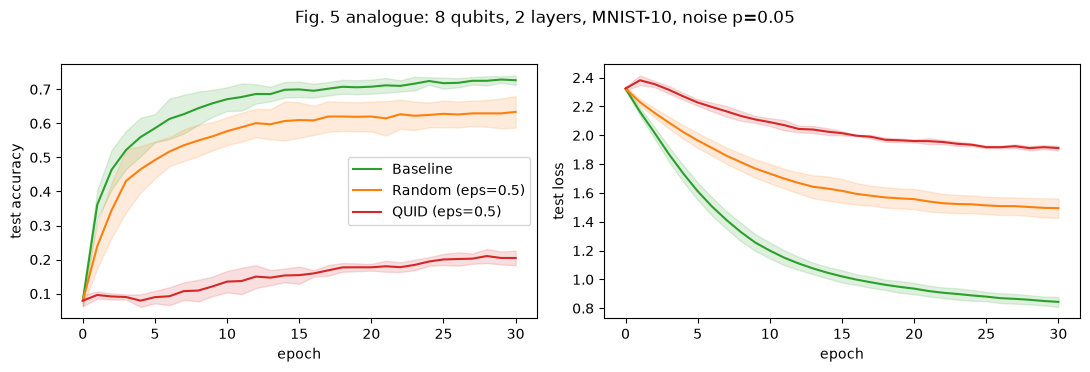

In [23]:
def run_fig5(method, p, seed, epochs=EPOCHS):
    key = ("fig5", method, p, seed, epochs)
    if key in RESULTS: return RESULTS[key]
    ftr, fte, ytr, yte = make_task(*IMAGES["mnist"], list(range(10)), N_FIG5, seed, n_feat=16)
    noise = PaperNoise(p); classes = list(range(10)); N = len(ytr)
    enc_tr, enc_te = Enc(ftr, 8, noise, ENC_SEQ, ENC_H), Enc(fte, 8, noise, ENC_SEQ, ENC_H)
    y = ytr.copy()
    if method != "clean":
        pidx = np.random.default_rng(10_000 + seed).permutation(N)[:N // 2]; cidx = np.setdiff1d(np.arange(N), pidx)
        y[pidx] = quid_labels(enc_tr.take(pidx), enc_tr.take(cidx), ytr[cidx], classes) if method == "quid" else random_flip(ytr, pidx, classes, np.random.default_rng(20_000 + seed))[pidx]
    m = QNN("PQC-1", 8, 10, noise, layers=2, rng=np.random.default_rng(seed))
    h = train_qnn(m, enc_tr, y, enc_te, yte, epochs, LR, BATCH, seed)
    RESULTS[key] = dict(acc=100 * h["test_acc"][-1], loss=h["test_loss"][-1], acc_curve=h["test_acc"], loss_curve=h["test_loss"])
    return RESULTS[key]

t0 = time.time(); F5 = {}
for p in ((P_NOISE,) if FAST_MODE else (P_NOISE, 0.0)):                        # the noiseless side check only in the full run
    for me in ("clean", "random", "quid"):
        F5[(p, me)] = [run_fig5(me, p, s) for s in SEEDS]
print(f"[{time.time()-t0:.0f} s]  8 qubits, 2 layers, MNIST-10 (d=16), eps = 0.5, final-epoch test accuracy % / test loss")
rows = [dict(noise_p=p, method=me, acc=pm([r["acc"] for r in v]), loss=pm([r["loss"] for r in v], 2)) for (p, me), v in F5.items()]
print(pd.DataFrame(rows).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for me, c in [("clean", "tab:green"), ("random", "tab:orange"), ("quid", "tab:red")]:
    for ax, key, lab in [(axes[0], "acc_curve", "test accuracy"), (axes[1], "loss_curve", "test loss")]:
        cv = np.array([r[key] for r in F5[(P_NOISE, me)]]); ax.plot(cv.mean(0), color=c, label={"clean": "Baseline", "random": "Random (eps=0.5)", "quid": "QUID (eps=0.5)"}[me])
        ax.fill_between(range(cv.shape[1]), cv.mean(0) - cv.std(0), cv.mean(0) + cv.std(0), color=c, alpha=0.15); ax.set_xlabel("epoch"); ax.set_ylabel(lab)
axes[0].legend(); plt.suptitle(f"Fig. 5 analogue: 8 qubits, 2 layers, MNIST-10, noise p={P_NOISE}", y=1.02); plt.tight_layout(); plt.show()
acc = {me: np.mean([r["acc"] for r in F5[(P_NOISE, me)]]) for me in ("clean", "random", "quid")}
los = {me: np.mean([r["loss"] for r in F5[(P_NOISE, me)]]) for me in ("clean", "random", "quid")}
extra_acc = acc["random"] - acc["quid"]; extra_loss = los["quid"] - los["random"]
claim("Section 6", "8-qubit model: QUID accuracy degradation beyond random flipping (points)", 41.0, extra_acc, "gap")
claim("Section 6", "8-qubit model: extra test loss of QUID vs random flipping", 0.4, extra_loss, "loss")
qclaim("Section 6", "QUID degrades the 8-qubit, 10-class model more than random flipping (accuracy lower and loss higher)", extra_acc > 0 and extra_loss > 0,
       f"accuracy {acc}; loss {los}")

### 5.7 Is the attack specific to the quantum model?

QUID labels depend on the *quantum* encoder (Hilbert-space distances), but the poisoned labels are just labels, so any classifier trained on them can suffer. Here the classical models
(trained on the same eight numbers and the same poisoned labels as the noiseless QNN of Table 4) show how far the labels alone do the damage.

Test accuracy (%) with the same (poisoned) training labels, noiseless QNN vs classical models:
       task         labels         QNN     SVC-rbf RandomForest      LogReg
    MNIST-4  clean eps=0.0 88.7 +- 2.1 96.3 +- 0.6  94.5 +- 0.5 92.5 +- 1.3
    MNIST-4 random eps=0.5 84.1 +- 3.4 92.7 +- 1.0  77.3 +- 3.0 87.7 +- 2.3
    MNIST-4   quid eps=0.5 38.5 +- 5.7 52.4 +- 4.9  51.8 +- 4.2 38.3 +- 1.7
  Fashion-4  clean eps=0.0 91.5 +- 2.0 95.2 +- 1.1  94.3 +- 1.2 94.9 +- 0.6
  Fashion-4 random eps=0.5 87.5 +- 3.5 91.9 +- 1.7  72.1 +- 3.2 89.9 +- 1.1
  Fashion-4   quid eps=0.5 45.8 +- 2.8 51.9 +- 7.4  51.3 +- 3.7 47.7 +- 2.1
Kuzushiji-4  clean eps=0.0 77.9 +- 1.8 91.1 +- 1.2  89.7 +- 1.3 85.4 +- 1.6
Kuzushiji-4 random eps=0.5 72.3 +- 4.9 83.5 +- 4.0  70.9 +- 2.8 78.2 +- 1.9
Kuzushiji-4   quid eps=0.5 44.1 +- 3.1 58.2 +- 2.1  52.5 +- 2.2 47.0 +- 3.2
  Letters-4  clean eps=0.0 71.5 +- 4.0 86.2 +- 1.1  82.3 +- 1.8 78.5 +- 1.3
  Letters-4 random eps=0.5 66.5 +- 2.2 76.2 +- 2.4  65.3 +- 2.4 71.0 

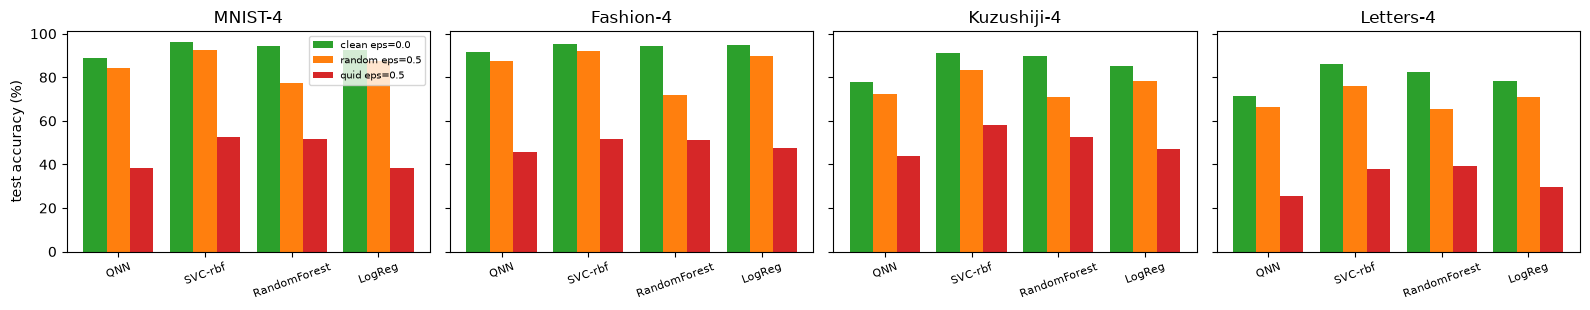


average over the four tasks, QUID labels : {'QNN': np.float64(38.5), 'SVC-rbf': np.float64(50.1), 'RandomForest': np.float64(48.8), 'LogReg': np.float64(40.7)}
average over the four tasks, random labels: {'QNN': np.float64(77.6), 'SVC-rbf': np.float64(86.1), 'RandomForest': np.float64(71.4), 'LogReg': np.float64(81.7)}


In [24]:
rows = []
for tname in TASKS:
    nl = ("paper", 0.0)
    for me, eps in [("clean", 0.0), ("random", 0.5), ("quid", 0.5)]:
        row = dict(task=tname, labels=f"{me} eps={eps}", QNN=pm(collect(tname, "PQC-1", nl, eps, me, SEEDS)))
        for mname in ("SVC-rbf", "RandomForest", "LogReg"): row[mname] = pm(collect(tname, "PQC-1", nl, eps, me, SEEDS, key=mname, classical=True))
        rows.append(row)
cl = pd.DataFrame(rows); print("Test accuracy (%) with the same (poisoned) training labels, noiseless QNN vs classical models:"); print(cl.to_string(index=False))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, tname in zip(axes, TASKS):
    sub = cl[cl.task == tname]; cols = ["QNN", "SVC-rbf", "RandomForest", "LogReg"]; xs = np.arange(len(cols))
    for k, (lab, c) in enumerate([("clean eps=0.0", "tab:green"), ("random eps=0.5", "tab:orange"), ("quid eps=0.5", "tab:red")]):
        vals = [float(sub[sub.labels == lab][c_].iloc[0].split(" +- ")[0]) for c_ in cols]; ax.bar(xs + k * 0.27 - 0.27, vals, 0.27, color=c, label=lab)
    ax.set_xticks(xs); ax.set_xticklabels(cols, rotation=20, fontsize=8); ax.set_title(tname)
axes[0].set_ylabel("test accuracy (%)"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
cq = {m_: np.mean([float(cl[(cl.task == t_) & (cl.labels == "quid eps=0.5")][m_].iloc[0].split(" +- ")[0]) for t_ in TASKS]) for m_ in ["QNN", "SVC-rbf", "RandomForest", "LogReg"]}
cr = {m_: np.mean([float(cl[(cl.task == t_) & (cl.labels == "random eps=0.5")][m_].iloc[0].split(" +- ")[0]) for t_ in TASKS]) for m_ in ["QNN", "SVC-rbf", "RandomForest", "LogReg"]}
print("\naverage over the four tasks, QUID labels :", {k: round(v, 1) for k, v in cq.items()}); print("average over the four tasks, random labels:", {k: round(v, 1) for k, v in cr.items()})

## 6. The paper's numbers next to this notebook's

Verdict rules (from the repository's conventions): a number is **reproduced** if it is within 2 accuracy points of the paper's value (0.2 for the loss gap);
otherwise the verdict says how it deviates: **not reached** (the notebook is on the unfavourable side of the claim: a clean/random accuracy lower than the paper's, a QUID accuracy
higher than the paper's, an attack gap smaller than claimed) or **exceeded** (on the favourable side). **Cannot be checked** is used for claims whose experiment cannot be repeated here.
Qualitative claims (orderings, trends) are judged separately because they are what the paper's argument rests on.

In [25]:
def verdict(paper, nb, kind, tol=2.0):
    d = nb - paper
    tol = 0.2 if kind == "loss" else tol
    if abs(d) <= tol: return "reproduced"
    if kind in ("acc", "gap", "loss"): return "exceeded" if d > 0 else "not reached"        # plain accuracy / attack gap: higher = more than claimed
    return "exceeded" if d < 0 else "not reached"                                          # QUID accuracy: lower = stronger attack than claimed

C = pd.DataFrame(CLAIMS)
C["gap"] = C.notebook - C.paper
C["verdict"] = [verdict(r.paper, r.notebook, r.kind) for r in C.itertuples()]
# ESS tables and figures (Section 3)
ess_rows = []
for m in METRICS:
    for tname in TASKS:
        ess_rows.append(dict(source="Table 2", claim=f"ESS label accuracy, {m}, {tname}", paper=PAPER_T2[m][tname], notebook=float(tab2.loc[m, tname]), kind="acc"))
for m in METRICS:
    for p_ in (0.0, P_NOISE):
        ess_rows.append(dict(source="Fig. 3", claim=f"ESS accuracy MNIST-10, {m}, p={p_}", paper=float(PAPER_F3.loc[m, p_]), notebook=float(fig3.loc[m, p_]), kind="acc"))
for enc_, nbrow in [("angle", "angle"), ("amplitude", "amplitude (one prep operation)")]:
    for p_ in NOISE_LEVELS_FIG4:
        ess_rows.append(dict(source="Fig. 4", claim=f"ESS accuracy MNIST-10 d=16, {enc_}{' (one prep operation)' if enc_=='amplitude' else ''}, p={p_}", paper=float(PAPER_F4.loc[enc_, p_]), notebook=float(fig4.loc[nbrow, p_]), kind="acc"))
E = pd.DataFrame(ess_rows); E["gap"] = E.notebook - E.paper; E["verdict"] = [verdict(r.paper, r.notebook, r.kind) for r in E.itertuples()]
C = pd.concat([E, C], ignore_index=True)

# qualitative claims from Section 3
avg_acc = tab2.mean(axis=1)
qclaim("Table 2", "Frobenius norm gives the best (or equal-best, within 1 point) average ESS accuracy of the three metrics", bool(avg_acc["frobenius"] >= avg_acc.max() - 1.0), str(avg_acc.round(1).to_dict()))
ratio = tsec / tsec["frobenius"]
qclaim("Table 2", "The Frobenius norm is much cheaper than the trace norm (paper: 4.5x)", bool(ratio["trace"] >= 3), "time ratio to Frobenius per pair: " + str(ratio.round(1).to_dict()))
qclaim("Table 2", "The Frobenius norm is cheaper than the Hilbert-Schmidt distance (paper: 3.4x)", bool(ratio["hs"] >= 1.5),
       "time ratio HS / Frobenius = " + f"{ratio['hs']:.2f}" + ": with the product-state shortcut both are one inner product, so the paper's gap is an implementation effect")
qclaim("Fig. 4", "Amplitude encoding keeps a higher ESS accuracy than angle encoding at every non-zero noise level (state-prep-as-one-operation variant)",
       bool((fig4.loc["amplitude (one prep operation)", [0.05, 0.1, 0.2]] > fig4.loc["angle", [0.05, 0.1, 0.2]]).all()),
       "amplitude one-op " + str(fig4.loc["amplitude (one prep operation)"].round(1).to_dict()) + " | amplitude compiled " + str(fig4.loc["amplitude (compiled gates)"].round(1).to_dict()) + " | angle " + str(fig4.loc["angle"].round(1).to_dict()))
qclaim("Fig. 4", "Angle-encoding ESS accuracy falls as noise grows", bool(fig4.loc["angle", 0.0] > fig4.loc["angle", 0.2]), str(fig4.loc["angle"].round(1).to_dict()))
quid_acc_wrong = np.mean([run_one(t_, "PQC-1", ("paper", P_NOISE), 0.5, "quid", SEEDS[0])["label_correct"] for t_ in TASKS])
qclaim("Sec. 4.2", "QUID writes (almost) never the true label (it picks the farthest class)", bool(quid_acc_wrong < 0.1), f"fraction of QUID labels equal to the true label: {100*quid_acc_wrong:.1f} %")

# non-checkable claims
cnc = pd.DataFrame([
    dict(source="Abstract", claim="Hardware results on real IBM devices", paper=np.nan, notebook=np.nan, kind="-", gap=np.nan, verdict="cannot be checked"),
    dict(source="Sec. 5.2", claim="Table 7 SS-DPA (semi-supervised) numbers: only plain DPA implemented", paper=np.nan, notebook=np.nan, kind="-", gap=np.nan, verdict="cannot be checked"),
    dict(source="Sec. 6", claim="Targeted attacks and secure dataset release (stated, no experiment)", paper=np.nan, notebook=np.nan, kind="-", gap=np.nan, verdict="cannot be checked")])
pd.set_option("display.max_rows", 400)
summary = C.groupby(["source", "verdict"]).size().unstack(fill_value=0)
for col in ("reproduced", "exceeded", "not reached"):
    if col not in summary: summary[col] = 0
summary = summary[["reproduced", "exceeded", "not reached"]]; summary["total"] = summary.sum(axis=1)
print("Numeric claims (within 2 accuracy points = reproduced):"); print(summary.to_string())
print(f"\nOverall: {int((C.verdict=='reproduced').sum())} of {len(C)} numeric values reproduced, {int((C.verdict=='exceeded').sum())} exceeded the claim, {int((C.verdict=='not reached').sum())} not reached.")
Q = pd.DataFrame(QCLAIMS); print("\nQualitative claims:"); print(Q[["source", "claim", "verdict"]].to_string(index=False))
print("\nDetails:"); [print(f" - [{r.source}] {r.claim}: {r.detail}") for r in Q.itertuples()]

Numeric claims (within 2 accuracy points = reproduced):
verdict    reproduced  exceeded  not reached  total
source                                             
Fig. 3              0         0            6      6
Fig. 4              2         1            5      8
Section 6           2         0            0      2
Table 2             0         3            9     12
Table 3             2        11            7     20
Table 4             1         5           14     20
Table 5             0         8            4     12
Table 6             5        16           25     46
Table 7             1         8            7     16

Overall: 13 of 142 numeric values reproduced, 52 exceeded the claim, 77 not reached.

Qualitative claims:
   source                                                                                                                                  claim        verdict
  Table 4                                                                   QUID < random flipping < clea

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [26]:
show = C.copy(); show["paper"] = show.paper.round(2); show["notebook"] = show.notebook.round(1); show["gap"] = show.gap.round(1)
print(pd.concat([show[["source", "claim", "paper", "notebook", "gap", "verdict"]], cnc[["source", "claim", "paper", "notebook", "gap", "verdict"]]], ignore_index=True).to_string(index=False))

   source                                                                    claim  paper  notebook   gap           verdict
  Table 2                                          ESS label accuracy, hs, MNIST-4  90.00      86.0  -4.0       not reached
  Table 2                                        ESS label accuracy, hs, Fashion-4  89.60      81.4  -8.2       not reached
  Table 2                                      ESS label accuracy, hs, Kuzushiji-4  69.30      76.9   7.6          exceeded
  Table 2                                        ESS label accuracy, hs, Letters-4  79.00      76.6  -2.4       not reached
  Table 2                                   ESS label accuracy, frobenius, MNIST-4  91.70      85.1  -6.6       not reached
  Table 2                                 ESS label accuracy, frobenius, Fashion-4  90.70      85.9  -4.8       not reached
  Table 2                               ESS label accuracy, frobenius, Kuzushiji-4  75.00      78.2   3.2          exceeded
  Table 

## 7. Reading the paper critically

* **What the evidence supports.** In every setting we tried (four datasets, noiseless, $p = 0.05$ and $p = 0.1$ noise, two device models, three circuits, an 8-qubit ten-class model) labels
  chosen by distance between encoded quantum states hurt the victim clearly more than random flips with the same budget once $\varepsilon \ge 0.5$ (Tables 3 to 6, Fig. 5; already at $\varepsilon = 0.3$ on three of four datasets), and the damage grows with $\varepsilon$, being negligible at $\varepsilon = 0.1$. This holds with a different data
  compression (PCA instead of the paper's autoencoder) and a different encoder detail, so it is not an accident of the paper's pipeline. The *ordering* QUID < random < clean is reproduced on every dataset; the *size* of the effect is not always.
* **The effect at $\varepsilon = 0.5$ is weaker here than in the paper, and noise does not make it stronger.** The paper reports 8 to 32 % accuracy for noisy PQC-1 at $\varepsilon = 0.5$ (Fashion-4: 7.9 %, below chance); here it is 25 to 49 %, and
  the noiseless and the $p = 0.05$ values are within about 3 points of each other, whereas the paper finds QUID "up to 24 points" stronger under noise. At $\varepsilon = 0.5$ half of the samples of each true class carry the true label and half a *consistent* wrong one, so
  the victim faces a tie, and which side wins depends on the training run (the standard deviation over our repetitions is 2 to 6 points). A below-chance accuracy at a tie needs the poisoned mapping to win in nearly every run; we did not see that. At $\varepsilon = 0.7$ the poisoned mapping is the majority and all datasets fall below
  chance here too (4 to 7 %), as in the paper.
* **Bi-level poisoning: the paper's conclusion is reversed here.** The paper finds that adding random poisoned samples makes QUID *less* damaging; here QUID with random features is *more* damaging than QUID label flipping on every dataset. The two protocols can differ in how
  the random features are drawn (not specified in the paper): uniform angles give the adversary states that are far from every class, so their QUID labels are strongly consistent.
* **Encoder-quality numbers are not matched.** Nearest-class ESS accuracy is 77 to 86 % here (paper: 75 to 92 %), and only 66 % on the ten-class problem (paper: 86 to 92 %). The most likely cause is the unspecified convolutional autoencoder, whose latent space was
  probably much better clustered than eight principal components. Amplitude encoding under noise is the opposite of the paper's picture in the compiled-gate reading (it collapses with noise) and weaker than the paper's in the one-operation reading; angle encoding follows the paper's trend.
* **The "no training, noise-resilient" cost model is real but the comparison is narrow.** PQC-1 is a product-state circuit, so QUID reduces to a product of single-qubit overlaps, a few lines of classical code for any qubit count, and a classical adversary could use Euclidean
  distances between the eight features in the same way (Exercise 2). The paper compares QUID with random flipping only. Section 5.7 shows the *labels* do the damage: an SVC, a random forest and a logistic regression trained on the same QUID labels fall from 88 to 92 % on average (clean) to 41 to 50 %, the QNN from 82 % to 39 %, whereas random flips cost them 5 to 19 points.
  Note also that the best classical model is 4 to 15 points more accurate than the 4-qubit QNN on clean data, which is not discussed in the paper.
* **The consistency of the wrong labels is what hurts.** Random flipping spreads the damage over three wrong classes and the true class stays the plurality; QUID sends the poisoned samples of a class to one (or two) wrong class(es), which looks like a second, coherent concept.
  The threshold in the paper is therefore the point where a wrong class becomes the plurality for some true class, a property of any consistent label shift, not of quantum state similarity. A data-sanitisation defence that compares each label with its neighbours' labels might counter much of it
  (untested here, Exercise 4); the paper dismisses sanitisation because the victim cannot intervene once the job is submitted.
* **Device-noise results do not follow from the devices' calibration.** With the calibration of the two IBM snapshots the gate noise changes $\langle Z\rangle$ by less than 0.005 for this circuit and the readout error is 0.9 % (Kyiv) to 2.4 % (Brisbane), so the runs behave like the noiseless ones (Section 5.4: baseline 88.6 %
  against 88.7 % noiseless). The paper's baselines under device noise are 4 to 11 points below its noiseless ones, and its QUID accuracy is 8 to 10 %. How the noise models were attached (qubits, transpilation level, readout) is not stated, which probably explains the difference.
* **No error bars.** The paper reports single numbers on 300 test images (one image is 0.33 points; the standard error near 85 % is about 2 points) and, as far as the text says, single runs. Our repetitions differ by 2 to 4 points for clean models and up to 10 for attacked ones, so many cell-to-cell differences in the
  paper's tables are inside the noise. Table 6 also contains entries that look like slips: the Kuzushiji-4 QUID value at $\varepsilon = 0.1$ (27.3) equals the one at $\varepsilon = 0.5$, and PQC-6 loses 18 points (72.6 to 54.3) to 10 % *random* flips while PQC-1 and PQC-8 lose less than 1 point.
* **Defence.** Plain DPA with $k = 3$ does not help at all here (change between -5 and +0.3 points at $\varepsilon = 0.5$); the paper's SS-DPA gains are +5, +9, +4 and -9 points at $\varepsilon = 0.5$, of the size of the run-to-run noise. Partitioning cannot help when every partition contains the same fraction of consistent wrong labels.
* **What would make the paper stronger.** Released code, the autoencoder, seeds, repeated runs with error bars, a classical farthest-class baseline, ESS timings on equal hardware, and an explicit statement of which rotation order and Hadamard the encoder uses (it matters a lot: Section 2.2 shows 42 %, 57 % and 90 % clean validation accuracy for three plausible readings of "$R_Z$ and $R_X$ encoding" in front of PQC-1).

## 8. Exercises

1. **A smarter random baseline.** Replace `random_flip` by a flip to the *same* random wrong class for all samples of a true class (a consistent permutation of labels). How much of QUID's advantage is just label consistency?
2. **A classical adversary.** Implement a QUID-like attack that uses Euclidean distances between the 8 scaled features (farthest class mean) instead of Hilbert-space distances. Compare it with QUID on the QNN and on the classical models.
3. **Targeted QUID.** Section 6 of the paper says QUID can flip only the labels of one class. Poison only class 0 of MNIST-4 and measure per-class recall of the victim.
4. **Defence by label sanitisation.** Before training, replace each label by the majority label among its $k$ nearest neighbours in the 8-dimensional feature space (Paudice et al.). How much of the QUID damage at $\varepsilon = 0.3$ and 0.5 does this undo?
5. **Where is the threshold?** Sweep $\varepsilon$ from 0.3 to 0.6 in steps of 0.05 on MNIST-4 with PQC-1 and find the ratio at which the QUID accuracy falls below the random-guess level; compare the location with the class-consistency argument in Section 7.

In [27]:
print(f"Total notebook runtime: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE={FAST_MODE})")

Total notebook runtime: 50.5 min (FAST_MODE=False)
